# EDA · Dari data mentah ke input EADRO

**Tujuan.** Menjelaskan, dengan data sungguhan dari *TT Dataset*, bagaimana empat jenis berkas mentah (`fault.json`, `metrics/*.csv`, `spans.json`, `logs.json`) diubah menjadi masukan model **EADRO** (Lee dkk., ICSE 2023). Setiap bagian menjawab tiga pertanyaan:

1. **Apa** prosesnya,
2. **Kenapa** proses itu diperlukan,
3. **Apa yang terlihat di data kita** (angka dan grafik dari data, bukan dari paper).

**Hubungan dengan `EDA.ipynb`.** `EDA.ipynb` memeriksa *kualitas* data (jam yang bergeser 8 jam, span duplikat, trace di luar jendela run, dst.). Notebook ini **tidak mengulang pemeriksaan itu**; ia memakai hasilnya (pembersihan yang sama) lalu melanjutkan ke pertanyaan berikutnya: *bagaimana data bersih itu menjadi tensor masukan model*. Notebook ini berdiri sendiri, jadi cukup *Run all* dari folder yang berisi `TT Dataset/`. Kebutuhan: Python 3.9+ dengan `numpy`, `pandas`, dan `matplotlib` (tidak ada pustaka lain; waktu jalan ±15–30 detik).

**Cara belajar dari notebook ini.** Baca kotak **Apa / Kenapa** sebelum tiap sel kode, lalu kotak **Cara membaca** sesudahnya. Angka yang saya tulis di kotak tersebut sudah dicocokkan dengan keluaran sel.

---

### Peta alur (angka di kiri = nomor bagian notebook)

```
 data mentah (per run)            proses                                              keluaran
 ─────────────────────            ──────                                              ────────
 fault.json      ─► [2] LABEL ─────────────────────────────────────────► y (ada anomali?)  dan  c (service biang)
                    [3] WINDOW: potong waktu jadi sampel (T detik, 27 service sekaligus)
 metrics/*.csv   ─► [4] KPI   ─► dilated causal conv + self-attention ──► H^K ─┐
 spans.json      ─► [5] TRACE ─► latensi per slot ─► conv + attention ───► H^T ─┼─► [8] FUSI ─► H^S ─► GAT ─► detektor + lokalisator
 logs.json       ─► [6] LOG   ─► event ─► Hawkes ─► FC ──────────────────► H^L ─┘                      ▲
 spans.json      ─► [5b] GRAF dependensi antar-service ────────────────────────────────────────────────┘
                    [7] membandingkan ketiga modalitas pada fault yang sama (alasan kita butuh fusi)
```

### Glosarium singkat

| Istilah | Arti |
|---|---|
| **Modalitas** | Satu jenis sumber data. Di sini ada tiga: **KPI** (metrics), **trace** (spans), dan **log**. |
| **Service (M)** | Satu microservice. Di TT ada **M = 27** service bisnis. Tiap service punya data KPI, trace, dan log sendiri. |
| **Window / sampel** | Potongan waktu sepanjang **T detik** dari **seluruh** service sekaligus. Satu window = satu sampel yang diberi label dan dimasukkan ke model. |
| **KPI** | *Key Performance Indicator*: angka pemakaian sumber daya per detik (CPU, memori, byte jaringan). |
| **Trace / span / latensi** | Satu *trace* = satu request end-to-end. Ia tersusun dari *span* (satu langkah di satu service). *Latensi* = lama sebuah span. |
| **Log event** | Pola kalimat log setelah bagian yang berubah-ubah (angka, ID) dibuang. Contoh: `Route id: <*>`. |
| **Hawkes process** | Model peluang kejadian yang menganggap kejadian lalu menaikkan peluang kejadian berikutnya (*self-exciting*). Dipakai EADRO untuk meringkas log. |
| **DCC** | *Dilated Causal Convolution*: penyaring pola pada deret waktu yang hanya melihat masa lalu dan bisa "melompat" agar jangkauannya luas. |
| **Self-attention** | Mekanisme agar tiap titik waktu menimbang titik waktu lain mana yang penting. |
| **Fusi** | Penggabungan representasi KPI, trace, dan log milik satu service menjadi satu vektor. **Ini bagian yang akan Anda kembangkan.** |
| **GLU** | *Gated Linear Unit*: separuh vektor dipakai sebagai nilai, separuh lagi (lewat sigmoid) sebagai "gerbang" pengatur seberapa banyak nilai itu lewat. |
| **GAT** | *Graph Attention Network*: jaringan saraf pada graf yang menimbang tetangga mana yang penting. Grafnya = ketergantungan antar-service. |
| **Detektor / lokalisator** | Dua kepala keluaran: apakah window ini anomali (ya/tidak), dan jika ya, service mana biang keroknya. |
| **HR@k, NDCG@k** | Ukuran lokalisasi: seberapa sering biang kerok ada di k peringkat teratas, dan seberapa tinggi peringkatnya. |

## 1. Persiapan dan satu run bersih

**Apa.** Sel di bawah mengatur *import*, lokasi data, fungsi pembaca, lalu memuat **satu run (R1)** dalam keadaan bersih dan sejajar waktu.

**Kenapa satu run saja.** Supaya setiap langkah mudah diikuti dan notebook ini cepat dijalankan. Semua run memakai format dan prosedur yang sama, jadi apa yang berlaku di R1 berlaku di run lain. Jika suatu angka memerlukan semua run (mis. jumlah sampel total), akan disebutkan eksplisit.

**Apa arti "bersih dan sejajar waktu".** Ringkasan dari temuan `EDA.ipynb`:

| Masalah di data mentah | Perlakuan |
|---|---|
| `fault.json` dan `metrics` memakai jam yang **tertinggal 8 jam** dari `spans`/`logs` | Waktu `spans` dan `logs` digeser **−28.800 detik** (`OFFSET_S`) sehingga semuanya memakai jam `fault.json`/`metrics` |
| `spans.json` berisi **±75% baris duplikat** | Hapus duplikat berdasarkan `(traceID, spanID)` |
| `spans.json` berisi trace **di luar waktu run** (sisa hari sebelumnya) | Simpan hanya trace yang mulai di dalam jendela run (toleransi 60 detik) |

Mulai dari titik ini, **semua waktu dalam notebook ini adalah detik pada jam `fault.json`/`metrics`**, dan sering dinyatakan *relatif terhadap awal run* (detik ke-0 = awal run).

In [1]:
from pathlib import Path
import json, re, tarfile, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "figure.autolayout": True})

# Path relatif terhadap lokasi notebook (folder "EADRO - APDM").
BASE    = Path("TT Dataset/TT Dataset")
DATA    = BASE / "data"          # 9 run dengan fault (sudah terekstrak)
NOFAULT = BASE / "no fault"      # 3 run tanpa fault (masih berupa arsip .tar.xz / .txz)
assert DATA.exists(), "Jalankan notebook dari folder yang berisi 'TT Dataset/' (EADRO - APDM)."

RUNS = sorted(p.name[3:] for p in DATA.glob("TT.2*") if p.is_dir())   # contoh: '2022-04-17T212101D2022-04-17T230842'
RID  = {run: f"R{i}" for i, run in enumerate(RUNS, 1)}                  # label pendek R1..R9
OFFSET_S = 8 * 3600                                                      # spans/logs lebih maju 8 jam dari fault.json/metrics (EDA.ipynb, Temuan 5)
def short(s):
    '''Nama pendek service untuk label: ts-contacts-service -> contacts.'''
    return s.removeprefix("ts-").removesuffix("-service")

COLORS = {"cpu_load": "#e07b39", "network_delay": "#4a7fb5", "network_loss": "#b5483a"}   # warna jenis fault

KPI_COLS = ["cpu_usage_system", "cpu_usage_total", "cpu_usage_user",
            "memory_usage", "memory_working_set", "rx_bytes", "tx_bytes"]               # 7 indikator KPI (kolom ke-2..8 di CSV)

# ---------------------------------------------------------------- pembaca berkas
def load_fault(run, base=DATA):
    with open(base / f"TT.fault-{run}.json") as f:
        return json.load(f)

def fault_table(run, base=DATA):
    '''Tabel fault: service (nama bersih), jenis fault, t_start, t_end. Waktu = epoch detik pada jam fault.json.'''
    ft = pd.DataFrame(load_fault(run, base)["faults"])
    ft["service"] = ft["name"].str.extract(r"^dockercomposemanifests_(ts-.+?)_\d+$")[0]   # buang prefix & suffix
    ft["t_start"] = ft["start"]
    ft["t_end"]   = ft["start"] + ft["duration"]
    return ft[["service", "fault", "t_start", "t_end", "duration"]]

EMPTY_WINDOWS = pd.DataFrame(columns=["service", "fault", "t_start", "t_end", "duration"])

LOG_RE = re.compile(
    r"^(?P<ts>\d{4}-\d\d-\d\d \d\d:\d\d:\d\d\.\d+)\s+(?P<level>[A-Z]+)\s+(?P<pid>\d+) --- "
    r"\[(?P<thread>[^\]]*)\]\s+(?P<logger>\S+)\s*: (?P<msg>.*)$", re.S)

def parse_logs(raw):
    '''raw = isi logs.json (dict service -> list baris teks). Hasil: satu baris per baris log, dengan kolom waktu t (epoch detik, UTC).'''
    rows = []
    for svc, lines in raw.items():
        for ln in lines:
            m = LOG_RE.match(ln)
            rows.append((svc, m["ts"], m["level"], m["msg"]) if m else (svc, None, None, ln))
    df = pd.DataFrame(rows, columns=["service", "ts_str", "level", "msg"])
    ts = pd.to_datetime(df["ts_str"], utc=True)
    df["t"] = (ts - pd.Timestamp("1970-01-01", tz="UTC")).dt.total_seconds()
    return df

SPAN_COLS = ["traceID", "spanID", "parent", "service", "op", "kind", "start", "dur"]

def flatten_spans(raw):
    '''raw = isi spans.json (list trace). Hasil: satu baris per span. start = epoch detik, dur = MIKRODETIK (sesuai aslinya).'''
    rows = []
    for tr in raw:
        proc = {k: v["serviceName"] for k, v in tr["processes"].items()}     # nama service ada di 'processes', bukan di span
        for s in tr["spans"]:
            tg = {t["key"]: t["value"] for t in s["tags"]}
            parent = s["references"][0]["spanID"] if s["references"] else None
            rows.append((tr["traceID"], s["spanID"], parent, proc[s["processID"]], s["operationName"],
                         tg.get("span.kind"), s["startTime"] / 1e6, s["duration"]))
    return pd.DataFrame(rows, columns=SPAN_COLS)

def trace_in_window(df, lo, hi, margin=60):
    '''True jika AWAL trace (span paling awal) jatuh di [lo-margin, hi+margin]. Berbasis trace agar satu trace tidak terpotong.'''
    t0 = df.groupby("traceID")["start"].transform("min")
    return (t0 >= lo - margin) & (t0 <= hi + margin)

def clean_spans_logs(raw_spans, raw_logs, lo, hi):
    '''Pembersihan yang sama untuk run berfault maupun no-fault. lo/hi = jendela run pada jam fault.json/metrics.'''
    sp = flatten_spans(raw_spans).drop_duplicates(["traceID", "spanID"]).reset_index(drop=True)   # 1) buang duplikat
    sp = sp[trace_in_window(sp, lo + OFFSET_S, hi + OFFSET_S)].copy()                            # 2) hanya trace di dalam run
    sp["start"] -= OFFSET_S                                                                      # 3) sejajarkan jam
    lg = parse_logs(raw_logs)
    lg = lg[(lg["t"] - OFFSET_S >= lo - 60) & (lg["t"] - OFFSET_S <= hi + 60)].copy()
    lg["t"] -= OFFSET_S
    return sp.reset_index(drop=True), lg.reset_index(drop=True)

def load_clean_run(run):
    '''Satu run BERFAULT yang bersih dan sejajar waktu (dict: windows, spans, logs, metrics, start, end).'''
    fj = load_fault(run)
    with open(DATA / f"TT.{run}" / "spans.json") as f: raw_sp = json.load(f)
    with open(DATA / f"TT.{run}" / "logs.json")  as f: raw_lg = json.load(f)
    sp, lg = clean_spans_logs(raw_sp, raw_lg, fj["start"], fj["end"])
    metrics = {p.stem: pd.read_csv(p) for p in sorted((DATA / f"TT.{run}" / "metrics").glob("*.csv"))}
    return {"run": run, "windows": fault_table(run), "spans": sp, "logs": lg, "metrics": metrics,
            "start": fj["start"], "end": fj["end"]}

def read_archive(path, parts=("metrics", "spans", "logs")):
    '''Baca satu run no-fault LANGSUNG dari arsip tar.xz/txz (tanpa ekstrak). Hanya bagian di `parts` yang dibaca.'''
    out = {"metrics": {}, "spans": None, "logs": None}
    with tarfile.open(path, "r:xz") as tf:
        for m in tf:
            if not m.isfile():
                continue
            p = Path(m.name).parts
            if p[-1] == "spans.json" and "spans" in parts:
                out["spans"] = json.load(tf.extractfile(m))
            elif p[-1] == "logs.json" and "logs" in parts:
                out["logs"] = json.load(tf.extractfile(m))
            elif len(p) >= 3 and p[-2] == "metrics" and "metrics" in parts:
                out["metrics"][Path(p[-1]).stem] = pd.read_csv(tf.extractfile(m))
    return out

def load_clean_nofault(path):
    '''Satu run NO-FAULT yang bersih. Tidak ada fault.json: jendela run diambil dari timestamp metrics.'''
    r = read_archive(path)
    ts = r["metrics"]["ts-order-service"]["timestamp"]
    lo, hi = float(ts.min()), float(ts.max())
    sp, lg = clean_spans_logs(r["spans"], r["logs"], lo, hi)
    return {"run": Path(path).name, "windows": EMPTY_WINDOWS, "spans": sp, "logs": lg,
            "metrics": r["metrics"], "start": lo, "end": hi}

# ---------------------------------------------------------------- muat R1 dan satu run no-fault (N1)
RUN1 = RUNS[0]
d = load_clean_run(RUN1)                                             # R1: berfault
N1 = load_clean_nofault(NOFAULT / "TT-no-fault.txz")                 # N1: tanpa fault (acuan "normal")

SERVICES = sorted(d["metrics"])                                      # urutan TETAP: dipakai sebagai indeks node graf & kelas lokalisasi
SID = {s: i for i, s in enumerate(SERVICES)}
M = len(SERVICES)
ACTIVE = sorted(d["spans"]["service"].unique())                      # service yang pernah muncul di trace (13 dari 27)

print(f"R1 = {RUN1}")
print(f"  jumlah service M = {M} | service yang muncul di trace = {len(ACTIVE)}")
print(f"  R1 : {len(d['spans']):>6,} span unik | {len(d['logs']):>6,} baris log | {len(d['windows'])} fault | durasi {(d['end']-d['start'])/60:.1f} menit")
print(f"  N1 : {len(N1['spans']):>6,} span unik | {len(N1['logs']):>6,} baris log | tanpa fault   | durasi {(N1['end']-N1['start'])/60:.1f} menit")
print()
print("27 service (urutan indeks 0..26):")
print(", ".join(f"{i}:{short(s)}" for i, s in enumerate(SERVICES)))

R1 = 2022-04-17T212101D2022-04-17T230842
  jumlah service M = 27 | service yang muncul di trace = 13
  R1 :  3,591 span unik |  8,995 baris log | 9 fault | durasi 107.7 menit
  N1 :  5,522 span unik | 13,668 baris log | tanpa fault   | durasi 135.1 menit

27 service (urutan indeks 0..26):
0:assurance, 1:auth, 2:basic, 3:cancel, 4:config, 5:contacts, 6:food-map, 7:food, 8:inside-payment, 9:notification, 10:order-other, 11:order, 12:payment, 13:preserve, 14:price, 15:route-plan, 16:route, 17:seat, 18:security, 19:station, 20:ticketinfo, 21:train, 22:travel-plan, 23:travel, 24:travel2, 25:user, 26:verification-code


**Cek cepat: apakah jam sudah sejajar?** Setelah pembersihan, awal `spans`, `logs`, dan `metrics` harus berada di sekitar detik ke-0 run. Pengecualian: log aplikasi baru muncul sekitar menit pertama karena baris log pertama berasal dari proses *login* workload (lihat Temuan 5a di `EDA.ipynb`).

In [2]:
t0 = int(np.floor(d["start"]))        # detik ke-0 run (jam fault.json/metrics)
rows = []
for name, x in (("R1", d), ("N1", N1)):
    t00 = int(np.floor(x["start"]))
    m = x["metrics"]["ts-order-service"]["timestamp"]
    rows.append({"run": name,
                 "metrics: awal (detik)": m.min() - t00, "metrics: akhir (detik)": m.max() - t00,
                 "span pertama (detik)": x["spans"]["start"].min() - t00, "span terakhir (detik)": x["spans"]["start"].max() - t00,
                 "log pertama (detik)": x["logs"]["t"].min() - t00, "log terakhir (detik)": x["logs"]["t"].max() - t00})
display(pd.DataFrame(rows).set_index("run").round(1))

,metrics: awal (detik),metrics: akhir (detik),span pertama (detik),span terakhir (detik),log pertama (detik),log terakhir (detik)
run,,,,,,
R1,0,6460,0.2,6406.3,60.4,6406.3
N1,0,8106,0.2,8090.7,60.4,8090.7


**Cara membaca.** Ketiga modalitas mulai dekat detik 0 (log sekitar detik 60) dan berakhir bersamaan dengan metrics. Itu berarti satu sumbu waktu bersama sudah terbentuk, dan syarat utama pembuatan *window* (bagian 3) terpenuhi: potongan waktu yang sama bisa diambil dari ketiga sumber.

## 2. Label (ground truth): apa yang harus ditebak model

**Apa.** `fault.json` mencatat kapan dan di service mana fault disuntikkan. EADRO mengubahnya menjadi **dua label** untuk setiap potongan waktu:

| Label | Isi | Tugas model |
|---|---|---|
| **y** | 1 jika ada fault aktif, 0 jika tidak | *Deteksi anomali* (klasifikasi biner) |
| **c** | indeks service yang sedang di-fault (0..26), atau "tidak ada" jika y = 0 | *Lokalisasi root cause* (memilih 1 dari 27 service) |

**Kenapa ini ground truth yang valid.** Fault dipasang sengaja oleh peneliti, jadi kita *tahu pasti* kapan dan di mana anomali terjadi. Di sistem produksi sungguhan label seperti ini tidak ada. Itulah alasan EADRO menyuntikkan fault di *testbed*.

**Dua hal teknis.**
1. Nama di `fault.json` berbentuk `dockercomposemanifests_ts-food-service_1` (nama *container*), sedangkan file metrics/log memakai `ts-food-service`. Awalan `dockercomposemanifests_` dan akhiran `_1` harus dibuang agar nama cocok. Itu yang dilakukan `fault_table`.
2. Label diberikan **per detik** dulu (array sepanjang run), baru nanti diringkas per window di bagian 3.

nama mentah  : dockercomposemanifests_ts-food-service_1
nama bersih  : ts-food-service (indeks 7)

R1 punya 6461 detik; 5400 detik abnormal (83.6%), 1061 detik normal (16.4%)


,service,fault,mulai (detik),selesai (detik),jeda sebelumnya (detik)
0,ts-food-service,cpu_load,3.1,603.1,NaN
1,ts-food-service,network_delay,717.6,1317.6,114.6
2,ts-food-service,network_loss,1442.0,2042.0,124.4
3,ts-travel-service,cpu_load,2156.9,2756.9,114.9
4,ts-travel-service,network_delay,2871.4,3471.4,114.4
5,ts-travel-service,network_loss,3595.7,4195.7,124.3
6,ts-contacts-service,cpu_load,4311.1,4911.1,115.4
7,ts-contacts-service,network_delay,5025.4,5625.4,114.2
8,ts-contacts-service,network_loss,5749.6,6349.6,124.3


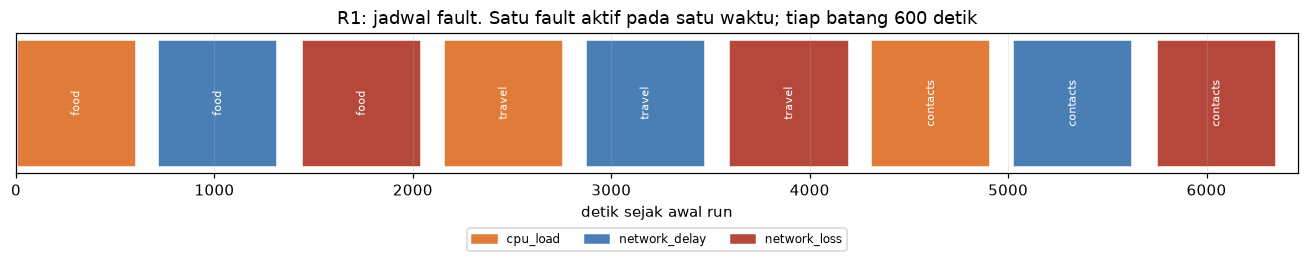

In [3]:
FAULT_ID = {"cpu_load": 0, "network_delay": 1, "network_loss": 2}
ID_FAULT = {v: k for k, v in FAULT_ID.items()}

def second_labels(x):
    '''Label per detik untuk satu run. Detik ke-i mewakili selang [t0+i, t0+i+1); dianggap abnormal jika titik tengahnya di dalam jendela fault.
    Hasil: (y, c, f)  y: bool (ada fault?), c: indeks service biang (-1 jika tidak ada), f: jenis fault (-1 jika tidak ada).'''
    t00 = int(np.floor(x["start"]))
    L = len(x["metrics"][SERVICES[0]])                    # jumlah detik = jumlah baris metrics
    mid = np.arange(L) + 0.5
    y = np.zeros(L, bool); c = np.full(L, -1); f = np.full(L, -1)
    for r in x["windows"].itertuples():
        m = (mid >= r.t_start - t00) & (mid < r.t_end - t00)
        y[m], c[m], f[m] = True, SID[r.service], FAULT_ID[r.fault]
    return y, c, f

y_sec, c_sec, f_sec = second_labels(d)
L1 = len(y_sec)

print("nama mentah  :", load_fault(RUN1)["faults"][0]["name"])
print("nama bersih  :", fault_table(RUN1)["service"].iloc[0], f"(indeks {SID[fault_table(RUN1)['service'].iloc[0]]})")
print(f"\nR1 punya {L1} detik; {y_sec.sum()} detik abnormal ({100*y_sec.mean():.1f}%), {(~y_sec).sum()} detik normal ({100*(~y_sec).mean():.1f}%)")

ft = d["windows"].copy()
ft["mulai (detik)"] = ft["t_start"] - t0
ft["selesai (detik)"] = ft["t_end"] - t0
ft["jeda sebelumnya (detik)"] = ft["mulai (detik)"] - ft["selesai (detik)"].shift(1)
display(ft[["service", "fault", "mulai (detik)", "selesai (detik)", "jeda sebelumnya (detik)"]].round(1))

fig, ax = plt.subplots(figsize=(12, 2.8))
for r in ft.itertuples():
    ax.barh(0, r.duration, left=r.t_start - t0, color=COLORS[r.fault], edgecolor="white")
    ax.text(r.t_start - t0 + r.duration / 2, 0, short(r.service), ha="center", va="center", fontsize=7.5, rotation=90, color="white")
ax.set_yticks([]); ax.set_xlabel("detik sejak awal run"); ax.set_xlim(0, L1)
ax.set_title("R1: jadwal fault. Satu fault aktif pada satu waktu; tiap batang 600 detik")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLORS[k]) for k in COLORS], labels=list(COLORS), loc="upper center",
          bbox_to_anchor=(0.5, -0.35), ncol=3, fontsize=8)
plt.show()

**Cara membaca.**
- Satu run = 9 fault berurutan (3 service × 3 jenis). Tiap fault 600 detik, **tidak pernah dua sekaligus**, dengan jeda ±2 menit.
- Karena itu **±84% detik di run berfault berstatus abnormal**. Waktu "normal" di dalam run berfault hanya jeda antar-fault. Untuk contoh normal dalam jumlah memadai, kita membutuhkan **run no-fault** (N1–N3, tiap run 135 menit tanpa fault). Paper menyebut 7 jam data fault-free; tiga run no-fault di sini berjumlah ±6,75 jam.
- Karena satu fault = satu service, **c selalu tepat satu kelas** pada window abnormal. Lokalisasi menjadi *klasifikasi 27 kelas*.

### Seberapa presisi batas label?

**Apa.** `fault.json` mencatat waktu perintah fault *dikirim*, bukan kapan dampaknya benar-benar mulai dan berhenti. Untuk fault `cpu_load` dampaknya tajam (CPU melonjak dari ±0,001 ke ±46), sehingga kita bisa mengukur selisih antara batas label dan batas dampak yang terlihat di metrics.

In [4]:
rows = []
for r in d["windows"].query("fault == 'cpu_load'").itertuples():
    mm = d["metrics"][r.service]; sec = (mm["timestamp"] - t0).to_numpy(); cpu = mm["cpu_usage_total"].to_numpy()
    a, b = r.t_start - t0, r.t_end - t0
    on  = sec[(sec >= a - 10) & (cpu > 1)][0]       # detik pertama CPU > 1 di sekitar awal label
    off = sec[(sec >= b - 10) & (cpu < 1)][0]       # detik pertama CPU kembali < 1 di sekitar akhir label
    rows.append({"service": r.service, "awal label (dtk)": a, "CPU mulai naik (dtk)": on, "selisih awal (dtk)": on - a,
                 "akhir label (dtk)": b, "CPU turun kembali (dtk)": off, "selisih akhir (dtk)": off - b})
display(pd.DataFrame(rows).round(1))

,service,awal label (dtk),CPU mulai naik (dtk),selisih awal (dtk),akhir label (dtk),CPU turun kembali (dtk),selisih akhir (dtk)
0,ts-food-service,3.1,2,-1.1,603.1,607,3.9
1,ts-travel-service,2156.9,2155,-1.9,2756.9,2761,4.1
2,ts-contacts-service,4311.1,4312,0.9,4911.1,4915,3.9


> **Temuan 2.** Batas label meleset **−2 sampai +1 detik di awal** dan **±4 detik di akhir** (CPU masih tinggi ±4 detik setelah waktu selesai di `fault.json`). Pada window 60 detik, selisih itu kurang dari 7% panjang window sehingga tidak berarti. Pada window kecil (mis. T = 10) ia menjadi bermakna, dan itu satu alasan lagi untuk tidak memakai T terlalu kecil.

## 3. Window: bagaimana waktu dipotong menjadi sampel

**Apa.** Model tidak membaca satu detik, melainkan satu **potongan waktu sepanjang T detik** dari *semua* service. Potongan itu disebut *observation window* dan satu window adalah **satu sampel**. Dua parameter menentukan segalanya:

| Parameter | Arti | Catatan |
|---|---|---|
| **T** | panjang window (detik) | **Paper tidak menyebut angkanya di teks** (hanya "T-length"). Harus kita putuskan atau diambil dari kode resmi. |
| **stride** | jarak geser antar window | stride = T → window tidak tumpang tindih. stride < T → lebih banyak sampel, tapi saling mirip. |

**Kenapa pilihan T penting.** T terlalu kecil → window kosong (terutama untuk trace yang jarang). T terlalu besar → satu window berisi campuran normal dan fault sehingga labelnya kabur.

**Aturan label window.** Kalau window sebagian di dalam fault, apakah ia abnormal? Paper hanya menulis "jika fault disuntikkan, window abnormal". Di notebook ini kita pakai: **abnormal jika ≥ 50% detiknya abnormal**, dan window yang sebagian (0% < bagian abnormal < 100%) ditandai *campuran* untuk dilaporkan. Ini keputusan desain yang bisa diubah.

Sel di bawah membandingkan beberapa nilai T pada R1: berapa window yang dihasilkan, berapa yang bersih/campuran, dan **berapa trace per window** (ini yang menentukan apakah modalitas trace punya isi).

In [5]:
trace_t0 = d["spans"].groupby("traceID")["start"].min()              # waktu mulai tiap trace (epoch detik)

rows = []
for T_ in (10, 30, 60, 120, 300):
    n = L1 // T_
    frac = y_sec[: n * T_].reshape(n, T_).mean(axis=1)               # bagian detik abnormal tiap window
    tr = np.bincount(np.clip(np.floor((trace_t0.to_numpy() - t0) / T_).astype(int), 0, None), minlength=n + 1)[:n]   # trace per window
    rows.append({"T (detik)": T_, "jumlah window": n,
                 "penuh fault": int((frac == 1).sum()), "campuran": int(((frac > 0) & (frac < 1)).sum()), "normal": int((frac == 0).sum()),
                 "trace/window (median)": float(np.median(tr)), "% window tanpa trace": 100 * float((tr == 0).mean())})
display(pd.DataFrame(rows).set_index("T (detik)").round(1))

,jumlah window,penuh fault,campuran,normal,trace/window (median),% window tanpa trace
T (detik),,,,,,
10,646,532,16,98,0.0,81.1
30,215,171,18,26,1.0,47.9
60,107,81,18,8,7.0,2.8
120,53,36,16,1,14.0,0.0
300,21,9,12,0,28.0,0.0


> **Temuan 3a.**
> - Dengan **T = 10 detik**, **±81% window tidak berisi satu pun trace** (beban kerja hanya ±7 trace per menit). Modalitas trace praktis kosong. Dengan **T = 60 detik**, median ±7 trace per window dan hanya ±3% window kosong.
> - Semakin besar T, semakin sedikit window **normal** di run berfault (T = 60: hanya ±8 dari 107). Itu mempertegas bahwa contoh normal harus datang dari run no-fault.
> - Jumlah window campuran nyaris tetap (12–18): tiap batas fault (awal dan akhir) menghasilkan satu window campuran. Karena jumlah window total menyusut saat T membesar, *persentase* window campuran ikut naik.
>
> **Kita pakai T = 60 detik sebagai nilai demonstrasi** dan menjadikannya parameter yang bisa diubah. Ini kompromi antara jumlah sampel dan isi trace, bukan nilai dari paper.

T=60, stride=60: 107 window | abnormal (>=50% detiknya abnormal): 90 | normal (<50%): 17 (terdiri dari 8 bersih + 9 campuran) | campuran total: 18


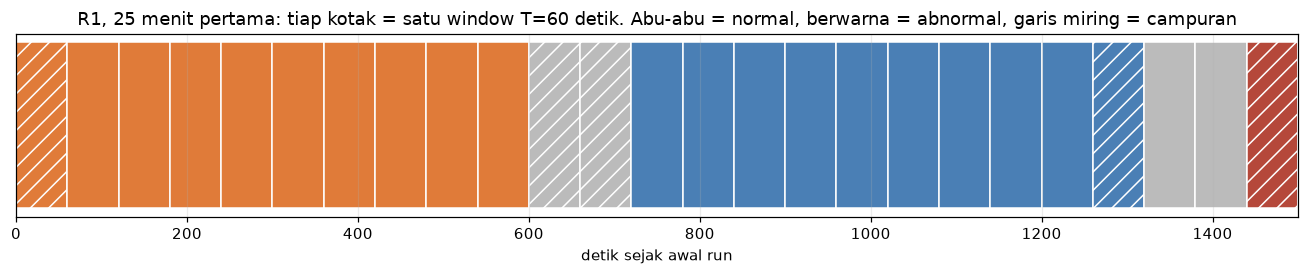

In [6]:
T = 60          # panjang window (detik)       <- parameter yang boleh Anda ubah
STRIDE = 60     # geser antar window           (stride = T: tidak tumpang tindih)
SLOT = 5        # lebar slot untuk deret latensi trace (detik); dijelaskan di bagian 5

n_win = (L1 - T) // STRIDE + 1
starts = np.arange(n_win) * STRIDE                                   # detik awal tiap window

def window_labels(y_sec, c_sec, f_sec, starts, T, thr=0.5):
    '''Ringkas label per detik menjadi label per window.
    y_win: abnormal jika bagian detik abnormal >= thr. c_win: service yang paling banyak jadi biang di window itu (-1 jika normal).'''
    frac = np.array([y_sec[s:s + T].mean() for s in starts])
    y_win = frac >= thr
    c_win = np.full(len(starts), -1)
    f_win = np.full(len(starts), -1)
    for k, s in enumerate(starts):
        cc = c_sec[s:s + T]; cc = cc[cc >= 0]
        if y_win[k] and len(cc):
            c_win[k] = np.bincount(cc).argmax()
            f_win[k] = np.bincount(f_sec[s:s + T][f_sec[s:s + T] >= 0]).argmax()
    return frac, y_win, c_win, f_win

frac, y_win, c_win, f_win = window_labels(y_sec, c_sec, f_sec, starts, T)
campuran = (frac > 0) & (frac < 1)
bersih_normal = int((frac == 0).sum())
print(f"T={T}, stride={STRIDE}: {n_win} window | abnormal (>=50% detiknya abnormal): {y_win.sum()} | "
      f"normal (<50%): {(~y_win).sum()} (terdiri dari {bersih_normal} bersih + {(~y_win).sum() - bersih_normal} campuran) | campuran total: {campuran.sum()}")

# Gambar: 25 menit pertama R1, tiap window diberi warna sesuai labelnya
fig, ax = plt.subplots(figsize=(12, 2.6))
for k, s in enumerate(starts):
    if s > 1500: break
    col = "#bbbbbb" if not y_win[k] else COLORS[ID_FAULT[f_win[k]]]
    ax.barh(0, T, left=s, color=col, edgecolor="white", hatch="//" if campuran[k] else None)
ax.set_yticks([]); ax.set_xlim(0, 1500); ax.set_xlabel("detik sejak awal run")
ax.set_title("R1, 25 menit pertama: tiap kotak = satu window T=60 detik. Abu-abu = normal, berwarna = abnormal, garis miring = campuran")
plt.show()

**Cara membaca.** Garis miring menandai window yang melintasi batas fault (sebagian normal, sebagian fault). Window seperti itu adalah *sumber derau label*: model dilatih menganggapnya abnormal padahal separuh isinya normal. Ada tiga pilihan yang masuk akal dan bisa dibandingkan nanti: (a) pakai ambang 50% seperti di sini, (b) anggap abnormal jika ada irisan sedikit pun, (c) buang window campuran dari data latih.

### Berapa sampel yang kita punya secara keseluruhan?
Sel berikut menghitung dari **label saja** (tanpa memuat spans/logs), untuk **9 run berfault + 3 run no-fault**, pada beberapa nilai T.

In [7]:
def n_rows_of_nofault(path):
    '''Jumlah detik sebuah run no-fault = jumlah baris salah satu CSV metrics.'''
    with tarfile.open(path, "r:xz") as tf:
        for m in tf:
            if m.isfile() and Path(m.name).parts[-2:-1] == ("metrics",):
                return len(pd.read_csv(tf.extractfile(m)))

NF_FILES = [NOFAULT / "TT-no-fault.txz",
            NOFAULT / "TT.2022-04-21T105158D2022-04-21T130705.tar.xz",
            NOFAULT / "TT.2022-04-21T153246D2022-04-21T174753.tar.xz"]
NF_LEN = [n_rows_of_nofault(p) for p in NF_FILES]
print("durasi run no-fault (detik):", NF_LEN, f"-> total {sum(NF_LEN)/3600:.2f} jam")

# label per detik semua run berfault (hanya dari fault.json + panjang metrics)
LAB = {}
for run in RUNS:
    L_run = len(pd.read_csv(DATA / f"TT.{run}" / "metrics" / "ts-order-service.csv"))
    x = {"start": load_fault(run)["start"], "windows": fault_table(run), "metrics": {SERVICES[0]: np.zeros(L_run)}}
    LAB[run] = second_labels(x)

rows = []
for T_ in (30, 60, 120):
    ab = ca = nm = 0
    for run in RUNS:
        yy, cc, ff = LAB[run]
        n = len(yy) // T_
        fr = yy[: n * T_].reshape(n, T_).mean(1)
        ab += int((fr >= 0.5).sum()); nm += int((fr < 0.5).sum()); ca += int(((fr > 0) & (fr < 1)).sum())
    n_nf = sum(n_ // T_ for n_ in NF_LEN)
    rows.append({"T (detik)": T_, "abnormal (run berfault)": ab, "normal di run berfault": nm, "normal di run no-fault": n_nf,
                 "TOTAL normal": nm + n_nf, "TOTAL sampel": ab + nm + n_nf, "(campuran, sudah termasuk di atas)": ca})
display(pd.DataFrame(rows).set_index("T (detik)"))

durasi run no-fault (detik): [8107, 8107, 8107] -> total 6.76 jam


,abnormal (run berfault),normal di run berfault,normal di run no-fault,TOTAL normal,TOTAL sampel,"(campuran, sudah termasuk di atas)"
T (detik),,,,,,
30,1624,311,810,1121,2745,162
60,810,153,405,558,1368,162
120,405,72,201,273,678,144


> **Temuan 3b.** Pada T = 60 kita mendapat **±810 sampel abnormal** dan **±560 sampel normal** (±405 dari tiga run no-fault, ±150 dari jeda di run berfault): **total ±1.370 sampel** tanpa tumpang tindih, dan 162 di antaranya adalah window campuran. Itu *sangat kecil* untuk ukuran deep learning, dan di bagian 9 terlihat bahwa sampel abnormal terbagi rata ke **27 kelas** lokalisasi (tepat 30 window per kelas). Konsekuensinya: (1) hasil sangat sensitif terhadap cara membagi data latih/uji, dan (2) perbandingan mekanisme fusi harus memakai **beberapa seed** agar selisih kecil tidak dianggap bermakna.

## 4. Modalitas KPI (metrics)

### 4.1 Apa isi satu file metrics: 8 kolom, tetapi hanya 7 yang merupakan KPI

**Apa.** `metrics/<service>.csv` berisi satu baris per detik. Ada **8 kolom**: satu kolom waktu (`timestamp`) dan **7 indikator**. Kolom waktu hanya dipakai untuk meluruskan data dengan jam run dan memotong window. **Ia bukan fitur** yang masuk ke model.

| Indikator | Arti (satuan tidak didokumentasikan di dataset; lihat kolom skala di 4.3) |
|---|---|
| `cpu_usage_system` | CPU yang dipakai kode *kernel* (sistem operasi) |
| `cpu_usage_user` | CPU yang dipakai kode aplikasi |
| `cpu_usage_total` | CPU total (kira-kira system + user) |
| `memory_usage` | Memori yang dipakai container |
| `memory_working_set` | Memori yang benar-benar "aktif" dipakai (tidak mudah dilepas OS) |
| `rx_bytes` | Byte **diterima** lewat jaringan pada detik itu |
| `tx_bytes` | Byte **dikirim** lewat jaringan pada detik itu |

Ketujuhnya sama dengan daftar KPI di paper (§V-A).

In [8]:
m = d["metrics"]["ts-travel-service"]
print("kolom file ts-travel-service.csv:", list(m.columns))
print(f"jumlah kolom = {m.shape[1]}  ->  1 kolom waktu + {m.shape[1]-1} indikator KPI;  jumlah baris = {m.shape[0]} (satu per detik)")
assert list(m.columns[1:]) == KPI_COLS
display(m.head(4))

kolom file ts-travel-service.csv: ['timestamp', 'cpu_usage_system', 'cpu_usage_total', 'cpu_usage_user', 'memory_usage', 'memory_working_set', 'rx_bytes', 'tx_bytes']
jumlah kolom = 8  ->  1 kolom waktu + 7 indikator KPI;  jumlah baris = 6461 (satu per detik)


,timestamp,cpu_usage_system,cpu_usage_total,cpu_usage_user,memory_usage,memory_working_set,rx_bytes,tx_bytes
0,1650172861,0.005,0.034998,0.03,0.003460,0.003443,4159.0,5896.5
1,1650172862,0.005,0.034998,0.03,0.003460,0.003443,4159.0,5896.5
2,1650172863,0.000,0.001210,0.00,0.003459,0.003442,0.0,0.0
3,1650172864,0.000,0.001210,0.00,0.003459,0.003442,0.0,0.0


### 4.2 Bentuk masukan: tensor `7 × T` per service

**Apa.** Untuk satu window, KPI satu service berbentuk matriks **7 baris (indikator) × T kolom (detik)**. Dengan 27 service, satu sampel KPI berukuran **27 × 7 × T**. Inilah yang masuk ke modul KPI (DCC + self-attention) dan diubah menjadi satu vektor **H^K** (64 angka) per service.

Sel berikut membangun tensor seluruh run R1 lalu memotongnya menjadi window.

In [9]:
def kpi_array(x):
    '''(M, L, 7): deret 7 indikator per detik untuk tiap service. Baris ke-i = detik ke-i sejak awal run (timestamp - t0).'''
    t00 = int(np.floor(x["start"]))
    L = len(x["metrics"][SERVICES[0]])
    out = np.zeros((M, L, len(KPI_COLS)))
    for s in SERVICES:
        mm = x["metrics"][s]
        out[SID[s]] = mm.set_index(mm["timestamp"] - t00)[KPI_COLS].reindex(range(L)).ffill().bfill().to_numpy(float)
    return out

def to_windows(arr, starts, T):
    '''arr: (M, L, ...) -> (n_win, M, ..., T) dengan sumbu waktu dipindah ke paling belakang.'''
    w = np.stack([arr[:, s:s + T] for s in starts])          # (n_win, M, T, ...)
    return np.moveaxis(w, 2, -1)                             # (n_win, M, ..., T)

KPI1 = kpi_array(d)                                          # seluruh run: (27, 6461, 7)
Xk = to_windows(KPI1, starts, T)                             # (n_win, 27, 7, T)
print("seluruh run R1   :", KPI1.shape, "= (service, detik, indikator)")
print(f"dipotong window  : {Xk.shape} = (window, service, indikator, detik)")
print(f"satu sampel      : {Xk[0].shape} = (service, indikator, detik) -> inilah 27 x 7 x {T}")
print(f"masukan modul KPI untuk SATU service pada SATU window: {Xk[0, SID['ts-travel-service']].shape}")

seluruh run R1   : (27, 6461, 7) = (service, detik, indikator)
dipotong window  : (107, 27, 7, 60) = (window, service, indikator, detik)
satu sampel      : (27, 7, 60) = (service, indikator, detik) -> inilah 27 x 7 x 60
masukan modul KPI untuk SATU service pada SATU window: (7, 60)


### 4.3 Skala nilai dan karakter data KPI

**Kenapa perlu dilihat.** Tujuh indikator memakai skala yang sangat berbeda. Jaringan saraf belajar buruk bila satu masukan bernilai ribuan sedangkan yang lain 0,003: masukan besar mendominasi. Jadi perlu **normalisasi**, dan normalisasi harus dihitung dari data **normal** (run no-fault), bukan dari data yang sudah berisi fault.

Sel berikut merangkum nilai KPI N1 (semua service digabung) dan satu sifat penting: **seberapa sering nilai sama persis dengan detik sebelumnya**.

In [10]:
KPIN1 = kpi_array(N1)                                        # (27, 8107, 7): data NORMAL
flat = KPIN1.reshape(-1, len(KPI_COLS))
same_prev = np.concatenate([(np.diff(KPIN1[i], axis=0) == 0) for i in range(M)])   # True jika sama dengan detik sebelumnya

scale = pd.DataFrame({
    "median": np.median(flat, axis=0), "persentil 99": np.percentile(flat, 99, axis=0), "maks": flat.max(axis=0),
    "% detik bernilai nol": 100 * (flat == 0).mean(axis=0),
    "% sama dgn detik sebelumnya": 100 * same_prev.mean(axis=0)}, index=KPI_COLS)
display(scale.round(5))

,median,persentil 99,maks,% detik bernilai nol,% sama dgn detik sebelumnya
cpu_usage_system,0.00000,0.01000,0.05000,92.02610,89.47876
cpu_usage_total,0.00094,0.00431,0.83523,0.00000,33.47863
cpu_usage_user,0.00000,0.01000,0.78000,95.08609,93.49362
memory_usage,0.00322,0.00476,0.00476,0.00000,99.02404
memory_working_set,0.00322,0.00474,0.00474,0.00000,99.02313
rx_bytes,0.00000,1495.50000,9471.00000,87.15696,83.65043
tx_bytes,0.00000,2159.50000,11923.00000,86.82574,83.47132


> **Temuan 4a (skala dan karakter KPI, data normal N1).**
> - **Skala sangat timpang.** Memori ±0,003 dan CPU normal ±0,001 (maksimum 0,8), tetapi `rx_bytes`/`tx_bytes` mencapai ribuan. Tanpa normalisasi, byte jaringan akan mendominasi.
> - **Sebagian besar detik bernilai nol.** `rx_bytes` dan `tx_bytes` bernilai 0 di ±87% detik, `cpu_usage_system` ±92%, dan `cpu_usage_user` ±95% (nilainya berkuantisasi kelipatan 0,01). Hanya `cpu_usage_total` yang kontinu. Service jarang menerima trafik karena beban kerja hanya ±7 request per menit; yang informatif adalah *lonjakan* sesekali, bukan nilai rata-ratanya.
> - **Nilai sering sama persis dengan detik sebelumnya**: memori ±99%, `rx`/`tx` ±83%, `cpu_usage_system`/`user` ±90%, `cpu_usage_total` ±33%. Sumber data tampak *menahan nilai terakhir* (*sample-and-hold*), jadi resolusi efektif lebih kasar daripada 1 detik dan deret KPI banyak berisi "anak tangga".

### 4.4 Seperti apa KPI saat normal dan saat tiap jenis fault?

Sel berikut mengambil **satu window 60 detik** dari `ts-travel-service` untuk empat keadaan: normal (jeda antar-fault), `cpu_load`, `network_delay`, dan `network_loss`. Lalu menampilkan CPU total (skala log), memori, dan byte jaringan.

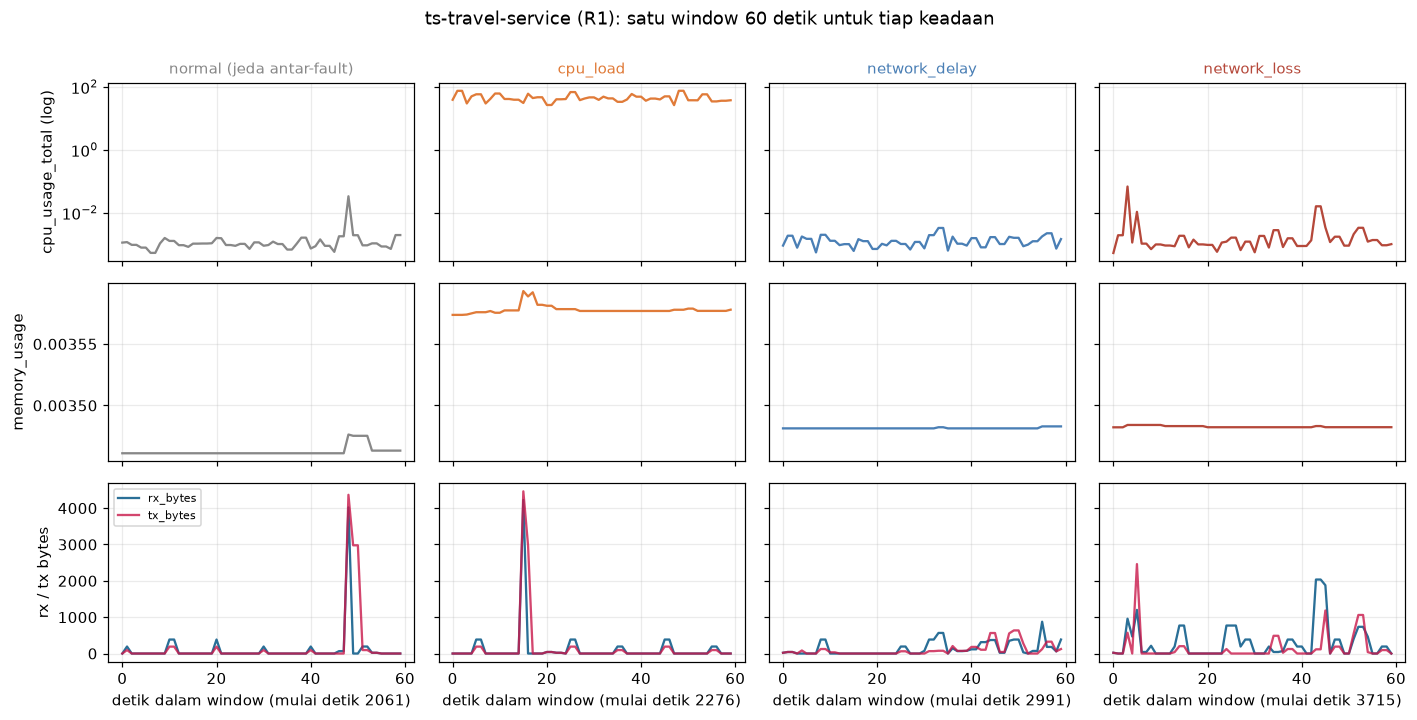


Rata-rata tiap indikator (service ts-travel-service):


,N1 (normal),cpu_load,network_delay,network_loss
cpu_usage_system,0.00073,0.07788,0.00075,0.00070
cpu_usage_total,0.00166,46.39607,0.00200,0.00199
cpu_usage_user,0.00084,46.15610,0.00123,0.00110
memory_usage,0.00354,0.00358,0.00348,0.00348
memory_working_set,0.00352,0.00355,0.00347,0.00347
rx_bytes,188.02806,148.75167,140.81333,224.56833
tx_bytes,232.74362,210.74083,160.53917,119.56667


Rasio terhadap N1 (1,0 = tidak berubah):


,cpu_load,network_delay,network_loss
cpu_usage_system,106.03,1.02,0.95
cpu_usage_total,27964.44,1.21,1.20
cpu_usage_user,54625.91,1.45,1.30
memory_usage,1.01,0.98,0.98
memory_working_set,1.01,0.98,0.98
rx_bytes,0.79,0.75,1.19
tx_bytes,0.91,0.69,0.51


In [11]:
svc = "ts-travel-service"
ftt = d["windows"].query("service == @svc").reset_index(drop=True)
first = ftt.iloc[0]
cases = [("normal (jeda antar-fault)", first.t_start - t0 - 95, "#888888")]
for r in ftt.itertuples():
    cases.append((r.fault, r.t_start - t0 + 120, COLORS[r.fault]))

fig, axes = plt.subplots(3, 4, figsize=(13, 6.5), sharex="col", sharey="row")
m = d["metrics"][svc]
for j, (name, a, col) in enumerate(cases):
    a = int(a); seg = m.iloc[a:a + T]; tt = np.arange(len(seg))
    axes[0, j].semilogy(tt, seg["cpu_usage_total"].clip(lower=1e-4), color=col)
    axes[1, j].plot(tt, seg["memory_usage"], color=col)
    axes[2, j].plot(tt, seg["rx_bytes"], color="#2a6f97", label="rx_bytes")
    axes[2, j].plot(tt, seg["tx_bytes"], color="#c9184a", label="tx_bytes", alpha=.8)
    axes[0, j].set_title(name, color=col, fontsize=10)
    axes[2, j].set_xlabel(f"detik dalam window (mulai detik {a})")
for i, lab in enumerate(["cpu_usage_total (log)", "memory_usage", "rx / tx bytes"]):
    axes[i, 0].set_ylabel(lab)
axes[2, 0].legend(fontsize=7)
fig.suptitle(f"{svc} (R1): satu window {T} detik untuk tiap keadaan", y=1.0)
plt.show()

# angka ringkas: rata-rata tiap indikator di dalam jendela fault vs rata-rata N1 (acuan normal) untuk service yang sama
base = KPIN1[SID[svc]].mean(axis=0)
rows = {"N1 (normal)": base}
for r in ftt.itertuples():
    a, b = int(r.t_start - t0), int(r.t_end - t0)
    rows[r.fault] = KPI1[SID[svc], a:b].mean(axis=0)
tab = pd.DataFrame(rows, index=KPI_COLS)
print("\nRata-rata tiap indikator (service ts-travel-service):")
display(tab.round(5))
print("Rasio terhadap N1 (1,0 = tidak berubah):")
display((tab.drop(columns="N1 (normal)").div(tab["N1 (normal)"].replace(0, np.nan), axis=0)).round(2))

> **Temuan 4b.**
> - `cpu_load`: **hanya CPU yang berubah**, dari ±0,001 menjadi ±46 (puluhan ribu kali lipat; `cpu_usage_system` ikut naik walau kecil). Memori dan jaringan nyaris tak berubah.
> - `network_delay` dan `network_loss`: **CPU dan memori tidak berubah bermakna** (CPU total ±0,0017 → ±0,0020: masih level derau). Satu-satunya jejak di KPI adalah pergeseran `rx`/`tx` yang kecil dan berisik (rasio 0,5–1,2). Artinya **KPI sendirian hampir buta terhadap fault jaringan**.
> - Ini persis argumen paper (§III-A): *tiap modalitas melihat jenis fault yang berbeda.* Bagian 7 akan menambahkan trace dan log ke gambaran ini.

### 4.5 Normalisasi: mengapa z-score saja bisa berbahaya di sini

**Apa.** *Z-score* mengubah nilai menjadi "berapa simpangan baku dari rata-rata normal": `z = (x − rata-rata normal) / simpangan baku normal`. Rata-rata dan simpangan baku diambil **dari data normal (N1) per service per indikator**.

**Kenapa perlu hati-hati.** CPU service yang menganggur hampir selalu ±0,001 dengan simpangan baku yang juga sangat kecil. Saat `cpu_load` membuat CPU menjadi ±46, nilai z-nya **ribuan hingga puluhan ribu**. Masukan sebesar itu bisa membuat pelatihan tidak stabil. Alternatifnya, setelah z-score dipakai *transformasi log bertanda* `sign(z)·log(1+|z|)` yang menekan nilai ekstrem tapi mempertahankan urutan.

Paper tidak menyebut cara normalisasinya. Jadi ini **keputusan yang harus Anda ambil dan catat** di laporan.

In [12]:
rows = []
for r in d["windows"].itertuples():
    a, b = int(r.t_start - t0), int(r.t_end - t0)
    k = KPI_COLS.index("cpu_usage_total")
    mu, sd = KPIN1[SID[r.service], :, k].mean(), KPIN1[SID[r.service], :, k].std()
    x = KPI1[SID[r.service], a:b, k].mean()
    z = (x - mu) / sd
    rows.append({"service": r.service, "fault": r.fault, "CPU total (rata2 di jendela)": x, "rata2 normal (N1)": mu, "std normal (N1)": sd,
                 "z-score": z, "sign(z)*log(1+|z|)": np.sign(z) * np.log1p(abs(z))})
display(pd.DataFrame(rows).round(4))

,service,fault,CPU total (rata2 di jendela),rata2 normal (N1),std normal (N1),z-score,sign(z)*log(1+|z|)
0,ts-food-service,cpu_load,46.2752,0.0014,0.0014,32569.8793,10.3912
1,ts-food-service,network_delay,0.0012,0.0014,0.0014,-0.1262,-0.1188
2,ts-food-service,network_loss,0.0012,0.0014,0.0014,-0.1361,-0.1276
3,ts-travel-service,cpu_load,46.3961,0.0017,0.0127,3639.5889,8.1999
4,ts-travel-service,network_delay,0.0020,0.0017,0.0127,0.0270,0.0267
5,ts-travel-service,network_loss,0.0020,0.0017,0.0127,0.0258,0.0255
6,ts-contacts-service,cpu_load,46.5269,0.0012,0.0013,35967.2840,10.4904
7,ts-contacts-service,network_delay,0.0011,0.0012,0.0013,-0.0723,-0.0698
8,ts-contacts-service,network_loss,0.0013,0.0012,0.0013,0.1039,0.0989


**Cara membaca.** Pada baris `cpu_load`, z-score mencapai **ribuan sampai puluhan ribu** (`ts-food-service` dan `ts-contacts-service` bahkan >30.000), sedangkan transformasi log menekannya menjadi ±8–11. Pada fault jaringan z-score kecil (CPU tidak berubah), seperti yang diduga. Untuk replikasi, pilihlah transformasi dan **fit hanya pada data latih normal** agar tidak ada kebocoran informasi dari data uji.

### 4.6 Bagaimana KPI diproses model: *dilated causal convolution* dan *self-attention*

Bagian ini hanya menjelaskan *mekanismenya* dengan contoh numpy kecil. Filter yang **dilatih** (64 buah) tidak kita latih di sini.

**Konvolusi 1D.** Sebuah jendela kecil (*kernel*, di EADRO 3 titik) digeser sepanjang deret waktu. Di tiap posisi ia menghitung **jumlah berbobot** tiga titik itu menjadi satu angka. Bobotnya adalah *filter* yang dipelajari; satu filter peka terhadap satu jenis pola (mis. lonjakan naik, atau osilasi). EADRO memakai **64 filter**, jadi dari deret 1 saluran lahir 64 saluran pola.

**Causal (kausal).** Keluaran di detik *t* **hanya memakai detik ≤ t**. Alasannya: pada saat memantau sungguhan kita belum punya data masa depan. Ini diwujudkan dengan menambah nol di sisi kiri (*padding*).

**Dilated.** Kernel tidak mengambil titik bertetangga, melainkan titik berjarak *d* (dilation). Dengan *d* = 1, 2, 4, … jangkauan melihat ke belakang (*receptive field*) bertambah cepat tanpa menambah parameter: untuk kernel 3 dan tiga lapis *d* = 1, 2, 4, jangkauannya `1 + 2·(1+2+4) = 15` detik.

> *Catatan:* EADRO sendiri memakai **satu lapis** per modalitas (paper §V-C). Demo di bawah memakai tiga lapis hanya agar jangkauan terlihat jelas.

**Self-attention** (paper, persamaan 2). Setelah konvolusi, tiap titik waktu "bertanya" ke semua titik lain: *titik mana yang penting untuk memahami saya?* Jawabannya berupa bobot (hasil *softmax*) yang dipakai membentuk rata-rata berbobot. Hasil akhir modul ini: **satu vektor `H^K` (64 angka) per service**. Cara persis deret diringkas menjadi satu vektor tidak dirinci di teks paper; perlu dicek di kode resmi.

masukan diubah di t=40  ->  keluaran berubah pada t = 40 .. 54  (15 titik)
tidak ada keluaran sebelum t=40 yang berubah (kausal): True
receptive field teoretis = 1 + (k-1)*sum(dilation) = 15 detik; terukur = 15 titik
bentuk: masukan (60,) -> keluaran (60,) (panjang tetap)


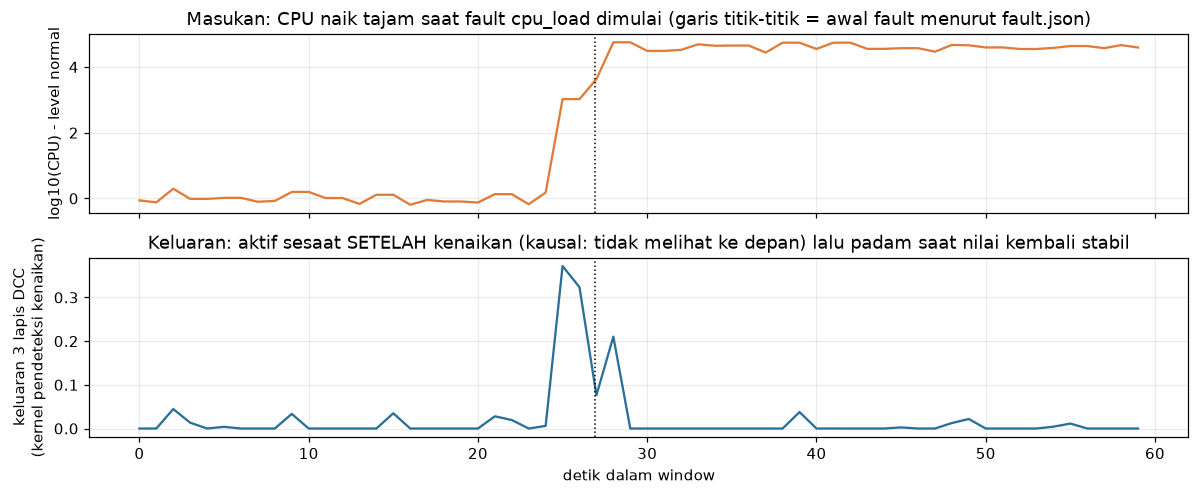

In [13]:
def dilated_causal_conv1d(x, w, dilation=1):
    '''y[t] = sum_i w[i] * x[t - (k-1-i)*dilation], dengan nol di sisi kiri. Panjang keluaran = panjang masukan.'''
    k = len(w); pad = (k - 1) * dilation
    xp = np.concatenate([np.zeros(pad), x])
    return np.array([sum(w[i] * xp[t + i * dilation] for i in range(k)) for t in range(len(x))])

def stack(x, kernels, dilations, relu=True):
    for w, dl in zip(kernels, dilations):
        x = dilated_causal_conv1d(x, w, dl)
        if relu: x = np.maximum(x, 0)
    return x

# Masukan: log10(CPU) service ts-travel-service pada 60 detik yang melewati awal fault cpu_load
a0 = int(ftt.iloc[0].t_start - t0) - 26
onset = ftt.iloc[0].t_start - t0 - a0                              # posisi awal fault (menurut fault.json) di dalam window ini
x = np.log10(KPI1[SID["ts-travel-service"], a0:a0 + 60, KPI_COLS.index("cpu_usage_total")].clip(1e-4))
x = (x - x[:20].mean()) / 1.0                                   # geser agar level normal ~ 0

DIL = [1, 2, 4]
edge = [np.array([-0.5, 0.0, 0.5])] * 3                         # kernel "pendeteksi kenaikan" (contoh, bukan hasil pelatihan)
avg = [np.array([1, 1, 1]) / 3] * 3                             # kernel perata-rata (untuk uji jangkauan)

y_edge = stack(x, edge, DIL, relu=True)

# Uji kausalitas dan jangkauan: ubah satu titik masukan lalu lihat keluaran mana yang ikut berubah
t_pert = 40
x2 = x.copy(); x2[t_pert] += 1.0
diff = np.nonzero(np.abs(stack(x2, avg, DIL, relu=False) - stack(x, avg, DIL, relu=False)) > 1e-12)[0]
print(f"masukan diubah di t={t_pert}  ->  keluaran berubah pada t = {diff.min()} .. {diff.max()}  ({len(diff)} titik)")
print(f"tidak ada keluaran sebelum t={t_pert} yang berubah (kausal): {bool(diff.min() >= t_pert)}")
print(f"receptive field teoretis = 1 + (k-1)*sum(dilation) = {1 + 2 * sum(DIL)} detik; terukur = {len(diff)} titik")
print("bentuk: masukan", x.shape, "-> keluaran", y_edge.shape, "(panjang tetap)")

fig, axes = plt.subplots(2, 1, figsize=(11, 4.6), sharex=True)
axes[0].plot(x, color="#e07b39"); axes[0].set_ylabel("log10(CPU) - level normal"); axes[0].axvline(onset, color="k", ls=":", lw=1)
axes[0].set_title("Masukan: CPU naik tajam saat fault cpu_load dimulai (garis titik-titik = awal fault menurut fault.json)")
axes[1].plot(y_edge, color="#2a6f97"); axes[1].set_ylabel("keluaran 3 lapis DCC\n(kernel pendeteksi kenaikan)")
axes[1].axvline(onset, color="k", ls=":", lw=1); axes[1].set_xlabel("detik dalam window")
axes[1].set_title("Keluaran: aktif sesaat SETELAH kenaikan (kausal: tidak melihat ke depan) lalu padam saat nilai kembali stabil")
plt.show()

**Cara membaca.**
- Uji di atas membuktikan dua sifat: perubahan di detik 40 **hanya** memengaruhi keluaran detik 40–54 (tidak ada yang sebelum 40, jadi *kausal*), dan rentangnya 15 titik sesuai rumus *receptive field*.
- Grafik bawah memperlihatkan bahwa filter pendeteksi-kenaikan aktif sesaat setelah CPU melonjak. Filter sungguhan dalam EADRO dipelajari dari data, jadi pola yang mereka tangkap tidak kita tetapkan; ini hanya ilustrasi mekanisme.
- Perhatikan bahwa CPU sebenarnya sudah naik ±2 detik **sebelum** garis fault.json (lihat "Seberapa presisi batas label?" di bagian 2). Batas label memang punya ketidakpastian beberapa detik.

## 5. Modalitas trace: latensi per service dan graf dependensi

### 5.1 Apa yang tersimpan di `spans.json`

`spans.json` berformat Jaeger: satu elemen = satu **trace** (satu request end-to-end), berisi beberapa **span** (satu langkah di satu service). Panggilan antar-service muncul sebagai pasangan span: **span client** di service pemanggil, lalu **span server** (anaknya) di service yang dipanggil. Satu trace contoh dibedah lengkap di `Contoh_Trace_1_Request.ipynb`.

EADRO memakai trace untuk **dua hal**:

| Kegunaan | Hasil | Bagian |
|---|---|---|
| Latensi tiap service dari waktu ke waktu | deret waktu → **H^T** | 5.2–5.4 |
| Siapa memanggil siapa | **graf dependensi** untuk GAT | 5.5 |

In [14]:
sp = d["spans"]
print(f"R1: {sp['traceID'].nunique()} trace, {len(sp):,} span unik  ->  rata-rata {len(sp)/sp['traceID'].nunique():.1f} span per trace")
print(f"jenis span: {sp['kind'].value_counts().to_dict()}")
print(f"service yang muncul di trace: {len(ACTIVE)} dari {M}")
print("  ada trace :", ", ".join(short(s) for s in ACTIVE))
print("  TANPA trace:", ", ".join(short(s) for s in SERVICES if s not in ACTIVE))

R1: 615 trace, 3,591 span unik  ->  rata-rata 5.8 span per trace
jenis span: {'server': 2112, 'client': 1479}
service yang muncul di trace: 13 dari 27
  ada trace : assurance, auth, basic, contacts, order-other, order, preserve, route, security, station, ticketinfo, travel, verification-code
  TANPA trace: cancel, config, food-map, food, inside-payment, notification, payment, price, route-plan, seat, train, travel-plan, travel2, user


### 5.2 Deret latensi: "rata-rata latensi per slot waktu per service"

**Apa.** Paper (§IV-A3): *"kami mengekstrak latensi dari trace dan mengubahnya menjadi deret waktu dengan menghitung **rata-rata latensi pada satu slot waktu untuk setiap callee**; slot tanpa invokasi diisi nol."* Dalam bahasa sederhana:

1. Bagi window menjadi slot-slot kecil (lebar `SLOT` detik).
2. Untuk service tertentu, kumpulkan semua span-**server**-nya yang mulai di slot itu (service itu sebagai *callee*, yaitu yang dipanggil).
3. Ambil rata-rata durasinya. Jika tak ada span di slot itu, isi **0**.

Hasilnya satu deret panjang `T / SLOT` per service, dan di window dengan 27 service: matriks `27 × (T/SLOT)`.

**Kenapa perlu diperiksa.** Paper memakai satu detik per slot untuk KPI. Untuk trace, kalau slot terlalu sempit hampir semuanya 0. Sel berikut mengukur **berapa persen slot yang berisi sedikitnya satu span**, untuk beberapa lebar slot.

In [15]:
def latency_slots(sp, t00, L, slot, kind="server"):
    '''Rata-rata durasi (ms) dan jumlah span per (service, slot). Slot tanpa span bernilai 0 (sesuai paper).'''
    n_slots = int(np.ceil(L / slot))
    s = sp[sp["kind"] == kind]
    idx = np.floor((s["start"].to_numpy() - t00) / slot).astype(int)
    ok = (idx >= 0) & (idx < n_slots)
    sid = s["service"].map(SID).to_numpy().astype(int)
    cnt = np.zeros((M, n_slots)); tot = np.zeros((M, n_slots))
    np.add.at(cnt, (sid[ok], idx[ok]), 1)
    np.add.at(tot, (sid[ok], idx[ok]), s["dur"].to_numpy()[ok] / 1000.0)        # mikrodetik -> ms
    mean = np.divide(tot, cnt, out=np.zeros_like(tot), where=cnt > 0)
    return mean, cnt

occ = {}
for slot in (1, 5, 10, 30, 60):
    _, cnt = latency_slots(d["spans"], t0, L1, slot)
    occ[f"slot {slot} dtk"] = (cnt[[SID[s] for s in ACTIVE]] > 0).mean(axis=1) * 100
occ = pd.DataFrame(occ, index=[short(s) for s in ACTIVE])
display(occ.round(1))
print("rata-rata 13 service aktif: ", occ.mean().round(1).to_dict())

,slot 1 dtk,slot 5 dtk,slot 10 dtk,slot 30 dtk,slot 60 dtk
assurance,1.4,6.9,13.8,41.2,82.4
auth,1.4,6.9,13.8,41.2,82.4
basic,1.5,7.3,14.5,42.6,82.4
contacts,1.4,7.0,14.1,40.7,79.6
order-other,1.4,6.8,13.6,40.7,81.5
order,1.6,7.7,15.1,43.5,84.3
preserve,1.3,6.7,13.4,40.3,80.6
route,2.0,9.0,16.5,44.4,86.1
security,1.4,6.8,13.6,40.7,81.5
station,1.8,8.0,15.9,44.4,83.3


rata-rata 13 service aktif:  {'slot 1 dtk': 1.5, 'slot 5 dtk': 7.2, 'slot 10 dtk': 14.3, 'slot 30 dtk': 41.8, 'slot 60 dtk': 82.1}


> **Temuan 5a (kejarangan trace).**
> - Dengan slot **1 detik**, hanya **±1,5%** slot berisi span; sisanya 0. Deret latensi nyaris datar di nol.
> - Dengan slot **5 detik** ±7%; **10 detik** ±14%; **30 detik** ±42%; **60 detik** ±82%.
> - Penyebabnya adalah beban kerja kecil (±7 trace per menit) dan **14 dari 27 service tidak punya satu pun span**. Deret latensi 14 service itu **0 sepanjang waktu**.
>
> Paper sendiri mengakui bahwa TrainTicket merespons lambat sehingga rekaman trace jarang. Untuk demo kita memakai **SLOT = 5 detik** (12 slot per window T = 60). Ini lagi-lagi **keputusan** yang perlu dibandingkan (mis. 5 vs 10 detik) sebelum dipakai dalam eksperimen.
>
> *Konsekuensi untuk fusi:* di sebagian besar service dan window, modalitas trace berisi hampir seluruhnya nol. Mekanisme fusi harus tahan terhadap modalitas yang "kosong".

### 5.3 Sisi client atau sisi server? Pilihan yang memengaruhi apa yang terlihat

Paper mendefinisikan *invocation latency* sebagai waktu dari pemanggilan sampai hasil kembali, **termasuk waktu komunikasi jaringan** antara pemanggil dan yang dipanggil. Di data, ada dua cara mengukurnya untuk satu panggilan:

- **Sisi server**: durasi span server milik callee (hanya waktu pemrosesan di callee).
- **Sisi client**: durasi span client milik caller (menunggu sampai balasan datang, jadi **mencakup jaringan**).

Sel berikut membandingkan keduanya untuk panggilan `ts-travel-service → ts-route-service` pada tiga jenis fault di `ts-travel-service` (service yang di-*fault* adalah pemanggil).

In [16]:
sp = d["spans"]
cl = sp[sp["kind"] == "client"][["traceID", "spanID", "service", "dur", "start"]].rename(
    columns={"spanID": "parent", "service": "caller", "dur": "dur_client", "start": "start_client"})
pairs = sp[sp["kind"] == "server"].merge(cl, on=["traceID", "parent"])             # span server + span client induknya
pairs = pairs[pairs["caller"] != pairs["service"]]
tr = pairs[(pairs["caller"] == "ts-travel-service") & (pairs["service"] == "ts-route-service")]

rows = [{"keadaan": "seluruh run", "jumlah panggilan": len(tr),
         "median durasi SISI SERVER (ms)": tr["dur"].median() / 1000, "median durasi SISI CLIENT (ms)": tr["dur_client"].median() / 1000}]
for r in ftt.itertuples():
    g = tr[(tr["start_client"] >= r.t_start) & (tr["start_client"] < r.t_end)]
    rows.append({"keadaan": f"travel: {r.fault}", "jumlah panggilan": len(g),
                 "median durasi SISI SERVER (ms)": g["dur"].median() / 1000 if len(g) else np.nan,
                 "median durasi SISI CLIENT (ms)": g["dur_client"].median() / 1000 if len(g) else np.nan})
display(pd.DataFrame(rows).set_index("keadaan").round(1))

,jumlah panggilan,median durasi SISI SERVER (ms),median durasi SISI CLIENT (ms)
keadaan,,,
seluruh run,427,2.1,2.4
travel: cpu_load,50,1.5,1.9
travel: network_delay,25,2.8,7290.6
travel: network_loss,12,2.5,1262.6


> **Temuan 5b.** Saat `ts-travel-service` kena `network_delay`, panggilannya ke `ts-route-service` terlihat berdurasi **±2,8 ms di sisi server** (route sendiri sehat) tetapi **±7.300 ms di sisi client** (jaringan di pihak pemanggil yang lambat). Sisi server **tidak melihat fault jaringan di pihak pemanggil**; sisi client melihatnya. Jumlah panggilan juga turun drastis (50 → 25 → 12) karena permintaan tertahan.
>
> Paper menulis bahwa latensi invokasi mencakup waktu komunikasi, yang lebih cocok dengan **sisi client**. Pilihan ini memengaruhi isi modalitas trace secara nyata, jadi sebaiknya dicatat dan, bila memungkinkan, dibandingkan. Notebook ini memakai sisi server sebagai default karena paling sederhana (sama seperti `EDA.ipynb`).

### 5.4 Contoh nyata: latensi `ts-travel-service` sepanjang run R1

Setiap titik adalah satu span server `ts-travel-service`. Sumbu y berskala log.

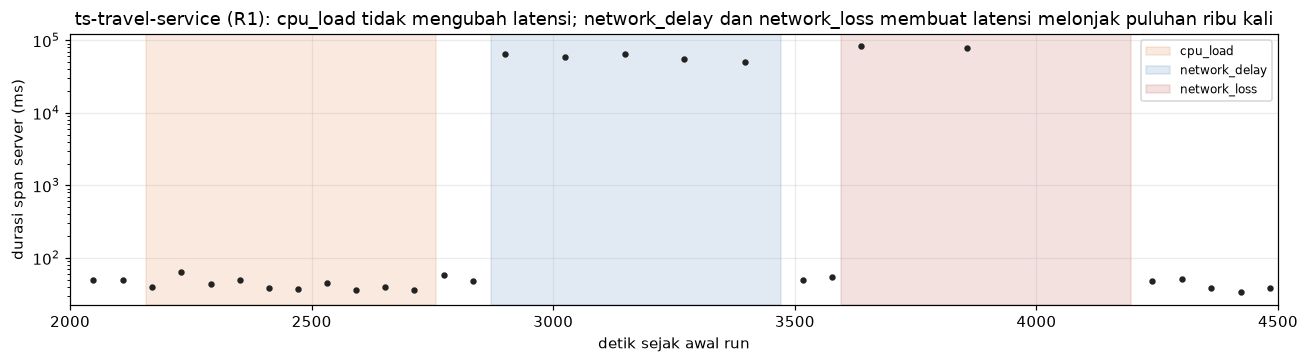

In [17]:
st = d["spans"].query("service == @svc and kind == 'server'")
fig, ax = plt.subplots(figsize=(12, 3.4))
for r in ftt.itertuples():
    ax.axvspan(r.t_start - t0, r.t_end - t0, color=COLORS[r.fault], alpha=0.16, label=r.fault)
ax.scatter(st["start"] - t0, st["dur"] / 1000, s=10, color="#222222")
ax.set_yscale("log"); ax.set_xlim(2000, 4500)
ax.set_xlabel("detik sejak awal run"); ax.set_ylabel("durasi span server (ms)")
ax.set_title("ts-travel-service (R1): cpu_load tidak mengubah latensi; network_delay dan network_loss membuat latensi melonjak puluhan ribu kali")
ax.legend(loc="upper right", fontsize=8); plt.show()

**Cara membaca.** Di jendela `cpu_load` (oranye) titik-titik tetap di ±40 ms: **trace tidak melihat fault CPU**. Di jendela `network_delay` (biru) dan `network_loss` (merah) hanya segelintir span yang selesai, dan durasinya melonjak ke puluhan detik. Sebagian besar permintaan tertahan sehingga **span-nya tidak pernah selesai di jendela itu**. Kekosongan itu sendiri informatif, dan itu sebabnya mengisi slot kosong dengan 0 (bukan membuangnya) penting.

### 5.5 Graf dependensi: siapa memanggil siapa

**Apa.** EADRO membangun **graf berarah** dari trace historis: tiap service = satu node; tiap pasangan *(callee, caller)* yang pernah terjadi = satu sisi. Paper (§IV-B1) mendefinisikan sisi `e(a,b)` = arah dari `a` ke `b` bila **`b` pernah memanggil `a`**, yaitu arah *dari yang dipanggil ke pemanggil*.

**Kenapa perlu.** Fault di satu service merambat ke service yang memanggilnya (pemanggil menunggu jawaban yang lambat). GAT memakai graf ini agar sebuah node "mendengar" keadaan tetangganya dan bisa menelusuri rambatan ke asalnya.

**Cara membangunnya dari data.** Untuk tiap span, lihat span induknya. Jika induk berada di service lain, itu satu panggilan lintas-service.

In [18]:
def edges_from_spans(sp):
    '''Panggilan lintas-service: span (service B) yang induknya berada di service A  =>  A memanggil B.  Hasil: callee, caller, jumlah.'''
    par = sp[["traceID", "spanID", "service"]].rename(columns={"spanID": "parent", "service": "caller"})
    j = sp.merge(par, on=["traceID", "parent"])
    j = j[j["caller"] != j["service"]]
    return j.groupby(["service", "caller"]).size().rename("jumlah").reset_index().rename(columns={"service": "callee"})

E1 = edges_from_spans(d["spans"])
display(E1.assign(arti=[f"{short(a)} memanggil {short(b)}" for a, b in zip(E1["caller"], E1["callee"])]))

A = np.zeros((M, M))
for r in E1.itertuples():
    A[SID[r.callee], SID[r.caller]] = 1          # sisi dari callee ke caller (konvensi paper)

# Apakah graf sama di setiap run? (hanya spans yang dimuat per run, 1-2 detik per run)
sets = {}
for run in RUNS:
    with open(DATA / f"TT.{run}" / "spans.json") as f: raw_sp = json.load(f)
    fj = load_fault(run)
    sp_r = flatten_spans(raw_sp).drop_duplicates(["traceID", "spanID"]).reset_index(drop=True)
    sp_r = sp_r[trace_in_window(sp_r, fj["start"] + OFFSET_S, fj["end"] + OFFSET_S)]
    e = edges_from_spans(sp_r)
    sets[RID[run]] = set(zip(e["callee"], e["caller"]))
union = set().union(*sets.values())
print("jumlah sisi per run:", {k: len(v) for k, v in sets.items()})
print(f"gabungan semua run: {len(union)} sisi | sisi yang ada di SEMUA run: {len(set.intersection(*sets.values()))}")
print("jumlah node dengan minimal satu sisi:", int(((A.sum(0) + A.sum(1)) > 0).sum()), "dari", M)

,callee,caller,jumlah,arti
0,ts-basic-service,ts-ticketinfo-service,178,ticketinfo memanggil basic
1,ts-contacts-service,ts-preserve-service,81,preserve memanggil contacts
2,ts-order-other-service,ts-security-service,88,security memanggil order-other
3,ts-order-service,ts-security-service,88,security memanggil order
4,ts-route-service,ts-travel-service,427,travel memanggil route
5,ts-security-service,ts-preserve-service,88,preserve memanggil security
6,ts-station-service,ts-basic-service,178,basic memanggil station
7,ts-station-service,ts-order-service,88,order memanggil station
8,ts-ticketinfo-service,ts-travel-service,168,travel memanggil ticketinfo
9,ts-verification-code-service,ts-auth-service,89,auth memanggil verification-code


jumlah sisi per run: {'R1': 10, 'R2': 10, 'R3': 10, 'R4': 10, 'R5': 10, 'R6': 10, 'R7': 10, 'R8': 10, 'R9': 10}
gabungan semua run: 10 sisi | sisi yang ada di SEMUA run: 10
jumlah node dengan minimal satu sisi: 12 dari 27


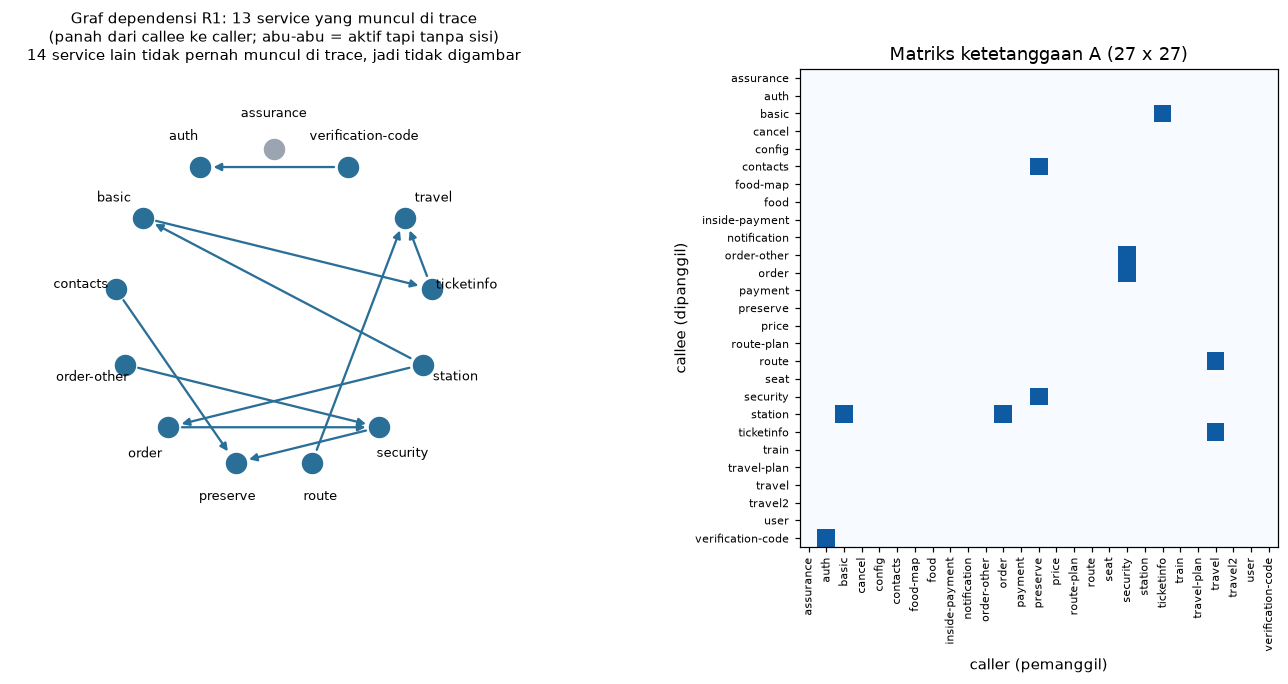

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [1, 1.1]})
# kiri: graf pada lingkaran, hanya service yang muncul di trace (13 node)
act = [SID[s] for s in ACTIVE]; K = len(act)
ang = np.linspace(0, 2 * np.pi, K, endpoint=False) + np.pi / 2
pos = {i: np.array([np.cos(a), np.sin(a)]) for i, a in zip(act, ang)}
deg = A.sum(0) + A.sum(1)
ax = axes[0]; ax.axis("off"); ax.grid(False)
for i in act:
    for j in act:
        if A[i, j]:
            ax.annotate("", xy=pos[j], xytext=pos[i], arrowprops=dict(arrowstyle="-|>", color="#2a6f97", lw=1.5, shrinkA=9, shrinkB=9))
for i in act:
    ax.scatter(*pos[i], s=170, color="#2a6f97" if deg[i] else "#9aa5b1", zorder=3)
    ax.text(*(pos[i] * 1.22), short(SERVICES[i]), ha="center", va="center", fontsize=8.5)
ax.set_xlim(-1.65, 1.65); ax.set_ylim(-1.5, 1.5); ax.set_aspect("equal")
ax.set_title(f"Graf dependensi R1: {K} service yang muncul di trace\n(panah dari callee ke caller; abu-abu = aktif tapi tanpa sisi)\n"
             f"{M - K} service lain tidak pernah muncul di trace, jadi tidak digambar", fontsize=10)
# kanan: matriks ketetanggaan 27 x 27
ax = axes[1]
ax.imshow(A, cmap="Blues", vmin=0, vmax=1.2); ax.grid(False)
ax.set_xticks(range(M)); ax.set_yticks(range(M))
ax.set_xticklabels([short(s) for s in SERVICES], rotation=90, fontsize=7)
ax.set_yticklabels([short(s) for s in SERVICES], fontsize=7)
ax.set_xlabel("caller (pemanggil)"); ax.set_ylabel("callee (dipanggil)"); ax.set_title("Matriks ketetanggaan A (27 x 27)")
plt.show()

> **Temuan 5c (graf).**
> - Hanya **10 sisi** dan **12 node** yang punya sisi. 15 dari 27 node *terisolasi* (tidak punya tetangga di graf). Ini wajar: 14 service tak muncul di trace sama sekali, dan satu service aktif (`assurance`) hanya dipanggil dari luar sistem.
> - **Graf identik di semua 9 run** (10 sisi, semuanya ada di setiap run; hanya jumlah panggilan yang bervariasi). Artinya graf cukup dibangun **sekali** dari data latih, sesuai paper yang memakai "trace historis".
> - **Implikasi untuk GAT:** untuk 15 node terisolasi, GAT tidak punya pesan dari tetangga. Representasi mereka sepenuhnya berasal dari KPI dan log milik sendiri (biasanya node diberi *self-loop* agar tidak hilang). Ini membuat kualitas fusi **lebih menentukan** justru untuk service yang paling sulit dilacak.

## 6. Modalitas log: dari teks mentah ke vektor intensitas

### 6.1 Log event dan *template*

**Apa.** Satu baris log memuat bagian tetap (ditulis programmer) dan bagian yang berubah-ubah (ID, angka, nama). Contoh:

```
Route id: 084837bb-53c8-4438-87c8-0321a4d09917        ->   Route id: <*>
Route id: aefcef3f-3f42-46e8-afd7-6cb2a928bd3d        ->   Route id: <*>
```

Kedua baris adalah **event yang sama** (`Route id: <*>`), hanya berbeda ID. Mengubah baris menjadi event disebut *log parsing*, dan kalimat tetapnya disebut *template*. EADRO memakai **Drain** (algoritma parsing berbasis pohon) untuk ini.

**Kenapa tidak membaca makna kalimat saja.** Paper memilih memodelkan **seberapa sering event muncul**, bukan arti kalimatnya (§IV-A1), karena (1) kualitas teks log bergantung kebiasaan programmer dan (2) membaca makna butuh model bahasa yang mahal.

**Catatan implementasi.** Drain tidak ada di lingkungan ini, jadi kita memakai *normalizer* sederhana berbasis regex untuk mengganti ID, token, angka, dan sejenisnya dengan `<*>`. Ini **pendekatan kasar** yang cukup untuk memahami data. Untuk replikasi, gunakan Drain (mis. paket `drain3`) dan bandingkan jumlah event yang dihasilkan.

**Satu hal khas data ini.** Sekitar 40% baris adalah `Span reported: <traceID>:<spanID>:<parentID>:<flags> - <operasi>`, yaitu jejak *reporter tracing*, bukan perilaku aplikasi. Template-nya dibuat per nama operasi.

In [20]:
UUID = re.compile(r"[0-9a-fA-F]{8}-[0-9a-fA-F]{4}-[0-9a-fA-F]{4}-[0-9a-fA-F]{4}-[0-9a-fA-F]{12}")
HEXID = re.compile(r"\b[0-9a-fA-F]{12,}\b")
JWT = re.compile(r"eyJ[\w\-\.]+")
NUM = re.compile(r"\b\d+(?:\.\d+)?\b")

def to_template(msg):
    '''Normalizer sederhana (pengganti kasar Drain): ganti bagian yang berubah-ubah dengan <*>.'''
    s = msg.strip()
    if s.startswith("Span reported:"):
        return "Span reported: <*> - " + s.split(" - ", 1)[-1]            # simpan nama operasinya
    s = JWT.sub("<*>", s); s = UUID.sub("<*>", s); s = HEXID.sub("<*>", s)
    s = re.sub(r"Route\{.*\}", "Route{<*>}", s)
    s = re.sub(r"Response\(.*\)", "Response(<*>)", s)
    s = re.sub(r"ServerDescription\{.*\}", "ServerDescription{<*>}", s)
    s = re.sub(r"\bat \w{3} \w{3} \d+ [\d:]+ \w+ \d{4}", "at <*>", s)
    s = re.sub(r"from .* -----> .* at", "from <*> -----> <*> at", s)
    return NUM.sub("<*>", s)

lg1, lgn = d["logs"].copy(), N1["logs"].copy()
for x in (lg1, lgn):
    x["tpl"] = x["msg"].map(to_template)
    x["is_span"] = x["msg"].str.startswith("Span reported:")

TPLS = sorted(set(lg1["tpl"]) | set(lgn["tpl"]))        # kosakata event (di replikasi nyata: dibentuk dari data LATIH saja)
TID = {t: i for i, t in enumerate(TPLS)}
L_EV = len(TPLS)
for x in (lg1, lgn):
    x["svc_i"] = x["service"].map(SID).astype(int); x["tpl_i"] = x["tpl"].map(TID).astype(int)

print(f"jumlah tipe event (L) dari R1 + N1 = {L_EV}   (R1 saja: {lg1['tpl'].nunique()}, N1 saja: {lgn['tpl'].nunique()})")
print(f"baris 'Span reported': {100*lg1['is_span'].mean():.1f}% dari log R1")
print(f"jumlah baris log per service di R1 (hanya service yang punya log): "
      f"{ {short(k): v for k, v in lg1.groupby('service').size().items()} }")
print("\ncontoh baris mentah -> template:")
ex = lg1[~lg1["is_span"]].drop_duplicates("tpl").sample(6, random_state=3)[["service", "msg", "tpl"]]
for r in ex.itertuples():
    print(f"  [{short(r.service)}]\n     mentah  : {r.msg[:110]}\n     template: {r.tpl[:110]}")

jumlah tipe event (L) dari R1 + N1 = 72   (R1 saja: 72, N1 saja: 60)
baris 'Span reported': 40.1% dari log R1
jumlah baris log per service di R1 (hanya service yang punya log): {'assurance': 176, 'auth': 528, 'basic': 528, 'contacts': 710, 'food': 3, 'order-other': 176, 'order': 704, 'preserve': 965, 'route': 880, 'security': 968, 'station': 264, 'ticketinfo': 352, 'travel': 2301, 'verification-code': 440}

contoh baris mentah -> template:
  [contacts]
     mentah  : FIND CONTACTS BY ID: 4e3d66de-7858-4683-aec8-6c6acebe8355
     template: FIND CONTACTS BY ID: <*>
  [security]
     mentah  : [Security Service][Get Order Num Info]
     template: [Security Service][Get Order Num Info]
  [contacts]
     mentah  : [Contacts-Query-Service][Query-Contacts] Result Size: 2
     template: [Contacts-Query-Service][Query-Contacts] Result Size: <*>
  [verification-code]
     mentah  :  AAAA  ___ st
     template: AAAA  ___ st
  [travel]
     mentah  : Exception in monitor thread while connecting to

**Cara membaca.** Setiap baris log kini punya nomor event (0..L−1). Dua catatan:
- **Hampir semua log berasal dari service yang menerima trafik.** `ts-food-service` hanya punya 3 baris log di seluruh R1 (karena tidak ada beban ke service itu), dan **ketiganya** adalah jejak koneksi MongoDB yang gagal lalu pulih (satu `Exception in monitor thread`, dua baris koneksi dibuka kembali). Itu contoh *log semantik* yang diceritakan paper (§III-A).
- Semua baris berlevel `INFO`; tidak ada `WARN`/`ERROR` (lihat `EDA.ipynb`). Karena itu mencari anomali lewat *level* log tidak akan berhasil; yang berguna adalah **isi** (event) dan **frekuensinya**.

### 6.2 Event occurrence per window

**Apa.** Dari baris-baris bernomor event, untuk tiap window kita hitung **berapa kali tiap event muncul di tiap service**. Hasilnya matriks `service × event` per window, yaitu `27 × L`. Inilah bahan mentah untuk model Hawkes.

In [21]:
def log_counts(lg, t00, starts, T):
    '''Jumlah kemunculan tiap event per service per window -> (n_win, M, L_EV).'''
    t = lg["t"].to_numpy() - t00; si = lg["svc_i"].to_numpy(); ti = lg["tpl_i"].to_numpy()
    out = np.zeros((len(starts), M, L_EV))
    for k, s in enumerate(starts):
        sel = (t >= s) & (t < s + T)
        np.add.at(out[k], (si[sel], ti[sel]), 1)
    return out

Xl = log_counts(lg1, t0, starts, T)
print("bentuk:", Xl.shape, "= (window, service, event)")
print(f"entri bukan-nol: {100*(Xl>0).mean():.2f}%  -> matriks SANGAT jarang (sparse): tiap service hanya memunculkan sebagian kecil dari {L_EV} tipe event")

bentuk: (107, 27, 72) = (window, service, event)
entri bukan-nol: 2.90%  -> matriks SANGAT jarang (sparse): tiap service hanya memunculkan sebagian kecil dari 72 tipe event


**Contoh nyata dari paper (Gambar 3): frekuensi sebuah event turun saat fault jaringan.** Paper memberi contoh event `Route id: <*>` dari service `route`. Saat fault jaringan, service pemanggilnya terhambat sehingga event itu makin jarang. Kita coba temukan hal yang sama di data kita: `ts-travel-service` memanggil `ts-route-service`; sementara `ts-travel-service` di-*fault*, apa yang terjadi pada jumlah event `Route id: <*>` di `ts-route-service`?

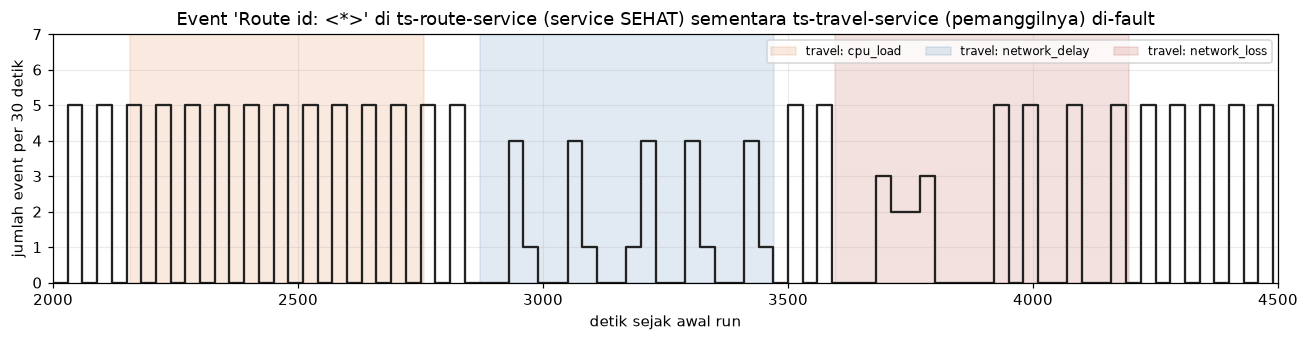

,event 'Route id' per menit
keadaan di travel,
N1 (tanpa fault),4.96
cpu_load,5.00
network_delay,2.50
network_loss,3.00


In [22]:
route_ev = lg1[(lg1["service"] == "ts-route-service") & (lg1["tpl"] == "Route id: <*>")]
bins = np.arange(2000, 4500 + 30, 30)
cnt, _ = np.histogram(route_ev["t"] - t0, bins=bins)

fig, ax = plt.subplots(figsize=(12, 3.2))
for r in ftt.itertuples():
    ax.axvspan(r.t_start - t0, r.t_end - t0, color=COLORS[r.fault], alpha=0.16, label=f"travel: {r.fault}")
ax.step(bins[:-1], cnt, where="post", color="#222")
ax.set_xlim(2000, 4500); ax.set_ylim(0, 7); ax.set_xlabel("detik sejak awal run"); ax.set_ylabel("jumlah event per 30 detik")
ax.set_title("Event 'Route id: <*>' di ts-route-service (service SEHAT) sementara ts-travel-service (pemanggilnya) di-fault")
ax.legend(loc="upper right", ncol=3, fontsize=8); plt.show()

rows = []
for r in ftt.itertuples():
    n_in = ((route_ev["t"] >= r.t_start) & (route_ev["t"] < r.t_end)).sum()
    rows.append({"keadaan di travel": r.fault, "event 'Route id' per menit": n_in / r.duration * 60})
nb = lgn[(lgn["service"] == "ts-route-service") & (lgn["tpl"] == "Route id: <*>")]
rows.insert(0, {"keadaan di travel": "N1 (tanpa fault)", "event 'Route id' per menit": len(nb) / (N1["end"] - N1["start"]) * 60})
display(pd.DataFrame(rows).set_index("keadaan di travel").round(2))

> **Temuan 6a.** Pola paper terulang di data kita: laju event `Route id: <*>` yang normalnya ±5 per menit **turun menjadi ±2,5 (network_delay) dan ±3 (network_loss)**, sedangkan saat `cpu_load` tetap ±5. Service `route` sendiri sehat; log-nya "sepi" karena **pemanggilnya terhambat**. Jadi *frekuensi event* adalah sinyal nyata, bahkan untuk service yang bukan sumber fault.

**Event yang hanya muncul saat fault.** Selain frekuensi, ada event yang **tidak pernah muncul di keadaan normal**. Tabel berikut menghitung tiap event di R1 menurut jenis fault yang sedang aktif, lalu menyaring yang kolom `normal`-nya 0.

In [23]:
def active_fault_at(t_abs):
    '''Jenis fault yang aktif pada waktu epoch t_abs (apa pun service-nya). -1 = tidak ada.'''
    i = np.floor(t_abs - t0).astype(int)
    out = np.full(len(i), -1)
    ok = (i >= 0) & (i < L1)
    out[ok] = f_sec[i[ok]]
    return out

lg1["f"] = active_fault_at(lg1["t"].to_numpy())
lg1["kondisi"] = lg1["f"].map({-1: "normal", **ID_FAULT})
tab = lg1.pivot_table(index=["service", "tpl"], columns="kondisi", values="msg", aggfunc="size", fill_value=0)
for c in ("normal", *FAULT_ID):
    if c not in tab.columns: tab[c] = 0
tab = tab[["normal", *FAULT_ID]]
only_fault = tab[(tab["normal"] == 0) & (tab[list(FAULT_ID)].sum(axis=1) > 0)]
only_fault = only_fault.reset_index().rename(columns={"tpl": "event (template)"}).rename_axis(columns=None)
only_fault["service"] = only_fault["service"].map(short)
print(f"{len(only_fault)} event yang HANYA muncul saat ada fault (dari {len(tab)} pasangan service-event di R1):")
with pd.option_context("display.max_colwidth", 105, "display.width", 220):
    display(only_fault)

13 event yang HANYA muncul saat ada fault (dari 81 pasangan service-event di R1):


,service,event (template),normal,cpu_load,network_delay,network_loss
0,contacts,"Closed connection [connectionId{localValue:<*>, serverValue:<*>}] to ts-contacts-mongo:<*> because th...",0,0,0,2
1,contacts,"Opened connection [connectionId{localValue:<*>, serverValue:<*>}] to ts-contacts-mongo:<*>",0,0,0,4
2,food,Exception in monitor thread while connecting to server ts-food-mongo:<*>,0,0,0,1
3,food,Monitor thread successfully connected to server with description ServerDescription{<*>},0,0,0,1
4,food,"Opened connection [connectionId{localValue:<*>, serverValue:<*>}] to ts-food-mongo:<*>",0,0,0,1
5,travel,"Closed connection [connectionId{localValue:<*>, serverValue:<*>}] to ts-travel-mongo:<*> because ther...",0,0,0,2
6,travel,Exception in monitor thread while connecting to server ts-travel-mongo:<*>,0,0,0,1
7,travel,I/O exception (java.net.NoRouteToHostException) caught when processing request to {}->http://ts-route...,0,0,0,1
8,travel,I/O exception (org.apache.http.NoHttpResponseException) caught when processing request to {}->http://...,0,0,0,1
9,travel,Monitor thread successfully connected to server with description ServerDescription{<*>},0,0,0,1


> **Temuan 6b.**
> - Ada **13 event yang tidak pernah muncul di keadaan normal**, dan semuanya muncul **hanya saat `network_loss`** (di R1). Di antaranya `I/O exception (java.net.NoRouteToHostException) … ts-route-service`, `Exception in monitor thread while connecting to server ts-*-mongo`, dan `Retrying request to … ts-route-service`. Event `Closed connection … socket exception` dan `Opened connection …` adalah jejak service memulihkan koneksi.
> - Karena EADRO memodelkan *keberadaan dan frekuensi* event (bukan kalimatnya), event langka seperti ini menjadi sinyal yang sangat bersih saat muncul.
> - **Peringatan skala:** tiap event hanya muncul **1–4 kali** dalam seluruh run. Jadi ia jarang jadi pembeda yang bisa diandalkan model; paper sendiri melaporkan log sebagai modalitas dengan kontribusi terkecil (Tabel IV).

### 6.3 Proses Hawkes: dari hitungan event ke "intensitas"

**Apa.** *Hawkes process* memodelkan peluang munculnya event pada waktu *t* sebagai
```
λ(t) = μ + Σ_{τ < t}  α · β · exp(-β · (t − τ))
```
Dibaca: peluang dasar **μ** (event muncul sendiri), ditambah **dorongan** dari tiap event sebelumnya pada waktu τ. Dorongan itu besar tepat setelah τ lalu **meluruh** (kecepatan peluruhan β). **α** menentukan kuat-lemahnya dorongan (jumlah event "lanjutan" yang dipicu satu event; α < 1 agar stabil). Karena event masa lalu *menaikkan* peluang event berikutnya, model ini disebut *self-exciting*.

**Kenapa dipakai untuk log.** Log sering muncul berombongan: satu request memicu beberapa baris sekaligus. Hawkes menangkap *kebaruan dan kerapatan* kemunculan lebih kaya daripada sekadar hitungan di window. Fault jaringan mengubah pola ini (event menjadi jarang, atau berburst saat percobaan ulang).

**Dalam EADRO.** Untuk tiap service dan tiap window, parameter model diestimasi dari timestamp event di window itu memakai pustaka `tick` (§IV-A1), lalu hasilnya menjadi **vektor intensitas Λ** sepanjang L. Λ dilewatkan ke satu lapisan FC dan jadi **H^L**. Bagaimana persisnya Λ dibentuk dari model terestimasi (misalnya intensitas di ujung window) perlu dicek di kode resmi.

> **Yang dilakukan sel di bawah:** hanya menghitung rumus λ(t) dengan **parameter ilustrasi** (μ = 0,04; α = 0,5; β = 0,1) untuk dua window nyata. **Bukan** hasil estimasi/pelatihan. Tujuannya melihat bentuk intensitasnya.

Jumlah event 'Route id' per window 60 detik, 10 window berurutan di dalam tiap fault ts-travel-service:


,w1,w2,w3,w4,w5,w6,w7,w8,w9,w10
cpu_load,5,5,5,5,5,5,5,5,5,5
network_delay,0,5,0,5,0,5,0,5,0,5
network_loss,0,3,4,3,0,5,5,2,3,5


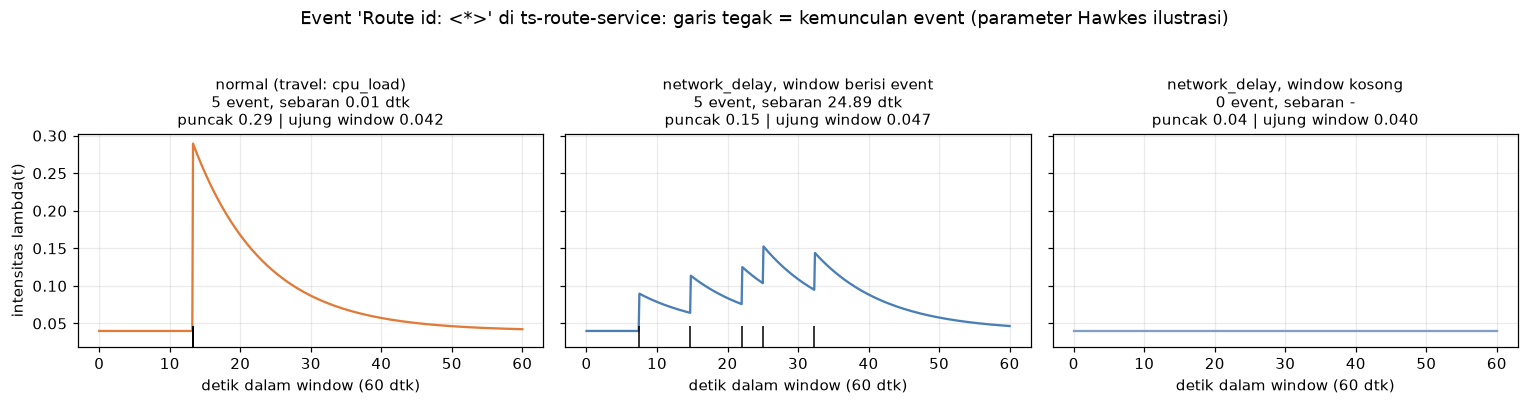

In [24]:
def hawkes_intensity(times, mu, alpha, beta, grid):
    '''lambda(t) = mu + sum_{tau<t} alpha*beta*exp(-beta*(t-tau)), dievaluasi di setiap titik `grid`.'''
    times = np.asarray(times)
    lam = np.full(len(grid), mu, float)
    for tau in times:
        dt = grid - tau
        lam += np.where(dt > 0, alpha * beta * np.exp(-beta * np.clip(dt, 0, None)), 0.0)
    return lam

MU, ALPHA, BETA = 0.04, 0.5, 0.1                     # parameter ILUSTRASI (bukan hasil estimasi)
grid = np.linspace(0, T, 601)
route_t = route_ev["t"].to_numpy() - t0               # waktu event 'Route id' (detik sejak awal run)

def window_events(a):
    e = route_t - a
    return e[(e >= 0) & (e < T)]

# 1) Berapa event per window berurutan (10 window) selama tiap fault milik travel?
tbl = {r.fault: [len(window_events(r.t_start - t0 + k * T)) for k in range(10)] for r in ftt.itertuples()}
print("Jumlah event 'Route id' per window 60 detik, 10 window berurutan di dalam tiap fault ts-travel-service:")
display(pd.DataFrame(tbl).T.rename(columns=lambda k: f"w{k + 1}"))

# 2) Bentuk event di dalam tiga window contoh
def first_window(fault_idx, cond):
    r = ftt.iloc[fault_idx]
    for k in range(10):
        a = r.t_start - t0 + k * T
        e = window_events(a)
        if cond(len(e)): return e
cases = [("normal (travel: cpu_load)", COLORS["cpu_load"], first_window(0, lambda n: n > 0)),
         ("network_delay, window berisi event", COLORS["network_delay"], first_window(1, lambda n: n > 0)),
         ("network_delay, window kosong", "#7f9fc4", first_window(1, lambda n: n == 0))]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, (name, col, ev) in zip(axes, cases):
    lam = hawkes_intensity(ev, MU, ALPHA, BETA, grid)
    ax.plot(grid, lam, color=col); ax.plot(ev, np.full(len(ev), MU * 0.8), "|", color="k", ms=14)
    sebar = f"{ev.max() - ev.min():.2f} dtk" if len(ev) else "-"
    ax.set_title(f"{name}\n{len(ev)} event, sebaran {sebar}\npuncak {lam.max():.2f} | ujung window {lam[-1]:.3f}", fontsize=9.5)
    ax.set_xlabel(f"detik dalam window ({T} dtk)")
axes[0].set_ylabel("intensitas lambda(t)")
fig.suptitle("Event 'Route id: <*>' di ts-route-service: garis tegak = kemunculan event (parameter Hawkes ilustrasi)", y=1.04)
plt.show()

**Cara membaca.**
- **Keadaan normal**: 5 event `Route id` muncul **hampir bersamaan** (dalam ±0,02 detik; satu request memicu lima pencarian rute sekaligus), lalu sunyi sekitar satu menit. Itulah *burst*: satu cluster rapat. Hawkes cocok untuk pola seperti ini: kurva melonjak tajam pada burst lalu meluruh perlahan.
- **Saat `network_delay`**: jumlah event per cluster sama (5), tetapi lima event itu **merenggang** sampai puluhan detik, dan clusternya datang tiap ±2 menit sehingga **separuh window T = 60 kosong**. Kurvanya lebih rendah dan lebar, dan di window kosong kurvanya datar di μ.
- Perhatikan tabel hitungan di atas: pada window normal, hitungan event 5 dan pada window `network_delay` yang berisi event juga 5. **Hitungan sederhana tidak membedakan keduanya, sedangkan bentuk waktunya berbeda.** Itu argumen untuk Hawkes (yang peka terhadap kerapatan dan kebaruan). Di sisi lain, window kosong (hitungan 0) memang mudah dibedakan oleh hitungan biasa.

*Pertanyaan terbuka yang layak diuji di proyek Anda:* seberapa jauh Hawkes benar-benar lebih baik daripada vektor **hitungan event** (`Xl` di 6.2) pada data ini? Itu bisa menjadi ablation tambahan, sekaligus jalan keluar bila `tick` sulit dipasang di Python versi baru.

## 7. Tiga modalitas pada fault yang sama: kenapa kita butuh fusi

**Apa.** Bagian ini menggabungkan hasil bagian 4–6 untuk menjawab pertanyaan inti penelitian Anda: *apakah setiap modalitas sama-sama berguna untuk setiap jenis fault?* Kalau tidak, cara menggabungkan modalitas (fusi) menjadi sangat penting.

**Cara.** Untuk satu service (`ts-travel-service`, service aktif yang di-*fault* di R1) kita hitung lima ukuran di tiap jendela fault, lalu membandingkannya dengan **acuan normal N1**:

| Modalitas | Ukuran |
|---|---|
| KPI | rata-rata `cpu_usage_total`; rata-rata `rx_bytes + tx_bytes` |
| Trace | jumlah span server per menit; median latensi (ms) |
| Log | jumlah baris log per menit (tidak termasuk `Span reported`) |

Acuannya N1, bukan "bagian normal R1", karena bagian normal R1 hanya ±17 menit (jeda antar-fault) dan terlalu pendek untuk laju trace/log yang jarang.

In [25]:
def modality_stats(x, svc, a, b):
    '''Ringkasan 3 modalitas untuk satu service pada selang [a, b) (epoch detik, jam metrics).'''
    dur = b - a
    mm = x["metrics"][svc]; sel = (mm["timestamp"] >= a) & (mm["timestamp"] < b)
    sv = x["spans"][(x["spans"]["service"] == svc) & (x["spans"]["kind"] == "server") & (x["spans"]["start"] >= a) & (x["spans"]["start"] < b)]
    lg = x["logs"][(x["logs"]["service"] == svc) & (x["logs"]["t"] >= a) & (x["logs"]["t"] < b)]
    lg = lg[~lg["msg"].str.startswith("Span reported:")]
    return {"KPI: CPU total (rata2)": mm.loc[sel, "cpu_usage_total"].mean(),
            "KPI: rx+tx byte (rata2)": (mm.loc[sel, "rx_bytes"] + mm.loc[sel, "tx_bytes"]).mean(),
            "Trace: span/menit": len(sv) / dur * 60,
            "Trace: median latensi (ms)": sv["dur"].median() / 1000 if len(sv) else np.nan,
            "Log: baris/menit": len(lg) / dur * 60}

rows, idx = [], []
for svc_ in ("ts-travel-service", "ts-contacts-service"):
    idx.append((svc_.replace("ts-", "").replace("-service", ""), "N1 (acuan normal)"))
    rows.append(modality_stats(N1, svc_, N1["start"], N1["end"]))
    for r in d["windows"].query("service == @svc_").itertuples():
        idx.append((svc_.replace("ts-", "").replace("-service", ""), r.fault))
        rows.append(modality_stats(d, svc_, r.t_start, r.t_end))
S = pd.DataFrame(rows, index=pd.MultiIndex.from_tuples(idx, names=["service", "keadaan"]))
print("Nilai absolut:")
display(S.round(3))

ratio = S.copy()
for svc_ in S.index.get_level_values(0).unique():
    ratio.loc[svc_] = S.loc[svc_].div(S.loc[(svc_, "N1 (acuan normal)")], axis=1).to_numpy()
print("Rasio terhadap N1 (1,0 = sama dengan normal; <1 = turun; >1 = naik):")
display(ratio.round(2))

Nilai absolut:


KPI: CPU total (rata2)  KPI: rx+tx byte (rata2)  Trace: span/menit  Trace: median latensi (ms)  Log: baris/menit
service       keadaan                                                                                                                            
travel        N1 (acuan normal)                   0.002                  420.824              0.999                      43.946            17.853
              cpu_load                           46.468                  359.492              1.000                      39.492            18.000
              network_delay                       0.002                  301.352              0.500                   58863.047             9.000
              network_loss                        0.002                  344.135              0.200                   80419.256            12.100
contacservice N1 (acuan normal)                   0.001                  208.157              1.984                       2.714             5.951
              cpu_load                           46.588                  218.229              2.000                       2.328             6.000
              network_delay                       0.001                  183.100              1.300                    7290.553             3.900
              network_loss                        0.001                  268.293              0.300                    3137.101             4.800

Rasio terhadap N1 (1,0 = sama dengan normal; <1 = turun; >1 = naik):


KPI: CPU total (rata2)  KPI: rx+tx byte (rata2)  Trace: span/menit  Trace: median latensi (ms)  Log: baris/menit
service       keadaan                                                                                                                            
travel        N1 (acuan normal)                    1.00                     1.00               1.00                        1.00              1.00
              cpu_load                         28006.85                     0.85               1.00                        0.90              1.01
              network_delay                        1.21                     0.72               0.50                     1339.44              0.50
              network_loss                         1.20                     0.82               0.20                     1829.96              0.68
contacservice N1 (acuan normal)                    1.00                     1.00               1.00                        1.00              1.00
              cpu_load                         39788.01                     1.05               1.01                        0.86              1.01
              network_delay                        0.92                     0.88               0.66                     2685.78              0.66
              network_loss                         1.11                     1.29               0.15                     1155.68              0.81

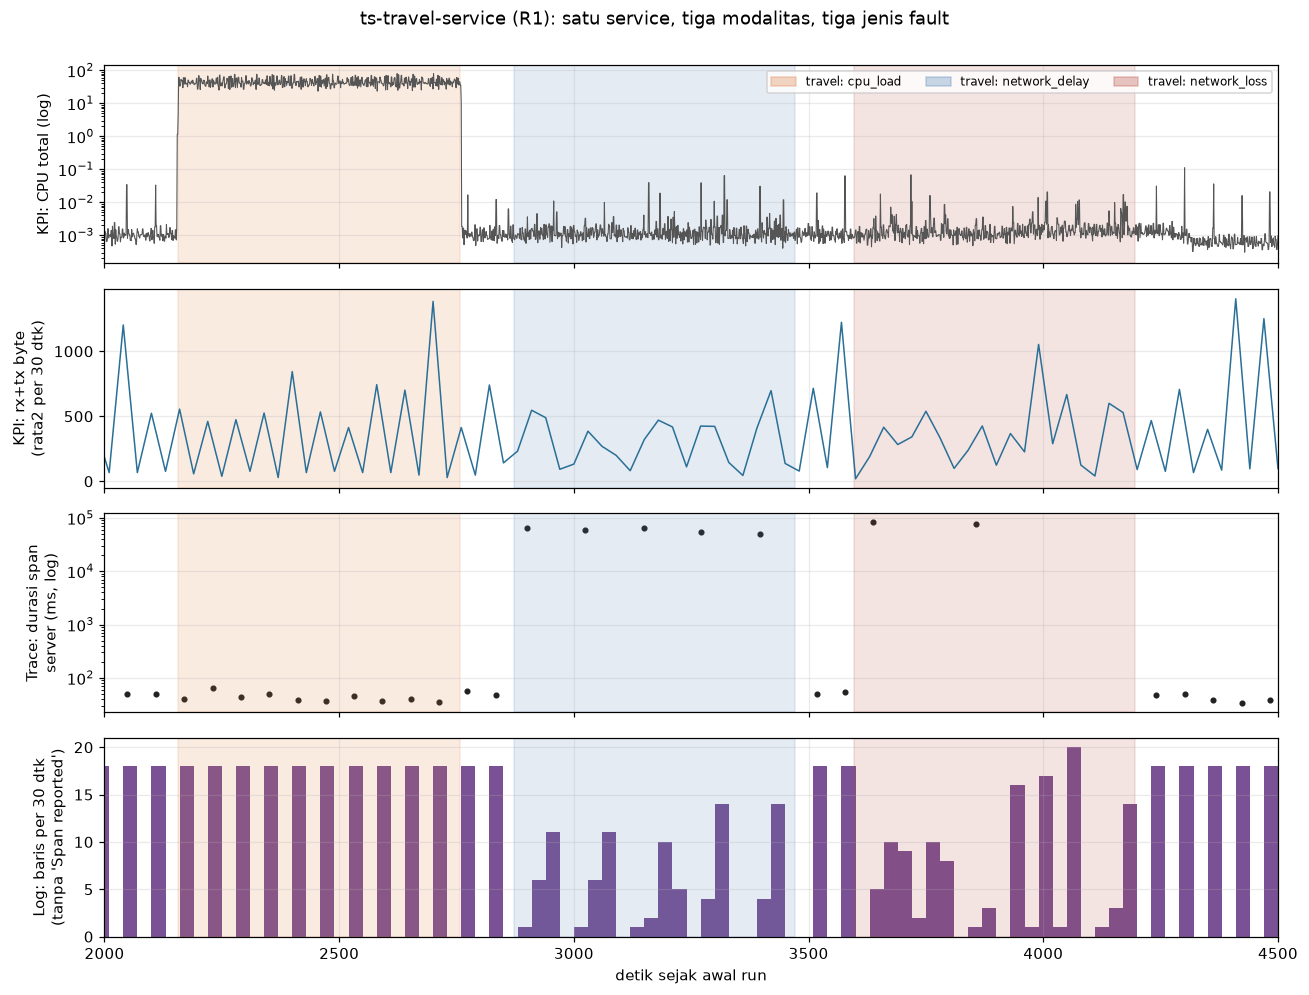

In [26]:
fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
xs = np.arange(L1)
cpu = KPI1[SID[svc], :, KPI_COLS.index("cpu_usage_total")]
rxtx = KPI1[SID[svc], :, KPI_COLS.index("rx_bytes")] + KPI1[SID[svc], :, KPI_COLS.index("tx_bytes")]
n30 = L1 // 30
axes[0].semilogy(xs, np.clip(cpu, 1e-4, None), color="#555", lw=.7); axes[0].set_ylabel("KPI: CPU total (log)")
axes[1].plot(np.arange(n30) * 30, rxtx[: n30 * 30].reshape(n30, 30).mean(1), color="#2a6f97", lw=1); axes[1].set_ylabel("KPI: rx+tx byte\n(rata2 per 30 dtk)")
axes[2].scatter(st["start"] - t0, st["dur"] / 1000, s=9, color="#222"); axes[2].set_yscale("log"); axes[2].set_ylabel("Trace: durasi span\nserver (ms, log)")
lgt = lg1[(lg1["service"] == svc) & (~lg1["is_span"])]
axes[3].hist(lgt["t"] - t0, bins=np.arange(0, L1 + 30, 30), color="#7a5195"); axes[3].set_ylabel("Log: baris per 30 dtk\n(tanpa 'Span reported')")
for ax in axes:
    for r in ftt.itertuples():
        ax.axvspan(r.t_start - t0, r.t_end - t0, color=COLORS[r.fault], alpha=0.15)
axes[0].set_xlim(2000, 4500); axes[3].set_xlabel("detik sejak awal run")
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLORS[k], alpha=.3) for k in COLORS], labels=[f"travel: {k}" for k in COLORS], loc="upper right", fontsize=8, ncol=3)
fig.suptitle(f"{svc} (R1): satu service, tiga modalitas, tiga jenis fault", y=1.0)
plt.show()

> **Temuan 7 (inti untuk topik fusi).** Pada `ts-travel-service`:
>
> | Fault | KPI (CPU) | KPI (jaringan) | Trace (jumlah & latensi) | Log (laju) |
> |---|---|---|---|---|
> | `cpu_load` | **naik puluhan ribu kali** | tidak jelas | tidak berubah | tidak berubah |
> | `network_delay` | tidak berubah bermakna | menurun sedikit | **jumlah span turun ±50%, latensi naik ±1.300×** | **turun ±50%** |
> | `network_loss` | tidak berubah bermakna | berubah sedikit | **jumlah turun ±80%, latensi naik ±1.800×** | turun ±30% |
>
> (Rasio CPU 1,2 pada fault jaringan berasal dari ±0,0017 menjadi ±0,0020: level derau, bukan sinyal.)
>
> Dengan kata lain, **tidak ada satu modalitas pun yang melihat ketiga jenis fault.** KPI hanya melihat `cpu_load`; trace dan log hanya melihat fault jaringan. Pola yang sama muncul di `ts-contacts-service` (angka berbeda, arah sama).
>
> **Hipotesis untuk eksperimen fusi Anda** (belum teruji; inilah yang dibuktikan atau dibantah penelitian Anda): karena modalitas yang informatif bergantung pada jenis fault, fusi yang bisa **menimbang modalitas secara adaptif** (gerbang, atensi) mungkin lebih baik daripada fusi yang memperlakukan ketiganya tetap sama (rata-rata, penjumlahan). Sebaliknya fusi adaptif lebih mahal; menimbang untung-ruginya adalah tujuan penelitian Anda.

## 8. Fusi: titik di mana ketiga modalitas bertemu

### 8.1 Apa dan kenapa

Setelah tiga encoder di bagian 4–6, **setiap service** memegang tiga vektor yang masing-masing berdimensi E = 64: `H^L` (log), `H^K` (KPI), `H^T` (trace). **Fusi** menggabungkannya menjadi satu vektor per service, `H^S`, yang masuk ke GAT.

Paper (§IV-B2) membedakan tiga strategi umum:

| Strategi | Digabung di mana | Contoh |
|---|---|---|
| *Early fusion* | di masukan mentah | menempel deret KPI, latensi, dan hitungan log lalu satu model |
| *Intermediate fusion* | di representasi hasil encoder | **EADRO**: menggabung `H^L`, `H^K`, `H^T` |
| *Late fusion* | di keputusan akhir | tiga model terpisah lalu voting |

EADRO memilih *intermediate fusion* karena (menurut literatur yang dikutip paper) biasanya memudahkan pemodelan lintas-modalitas. **Paper tidak menguji pilihan ini**: tidak ada eksperimen yang membandingkan strategi atau mekanisme fusi lain. Itulah celah penelitian Anda.

### 8.2 Fusi bawaan EADRO: `concat → FC → GLU`

1. **Concat**: tempel ketiganya, 64 + 64 + 64 = **192** angka.
2. **FC** (*fully connected*): satu lapisan linear memproyeksikan 192 → **128** (= 2E), lebih ringkas.
3. **GLU**: bagi 128 menjadi dua separuh (masing-masing 64). Separuh pertama `a` adalah *nilai*; separuh kedua `g` diubah sigmoid menjadi **gerbang** antara 0 dan 1. Keluaran = `a ⊗ sigmoid(g)` (perkalian per elemen), sehingga setiap dimensi bisa "dibuka" atau "ditutup". Hasil akhir **H^S** berdimensi **64**.

Sel berikut menunjukkan **bentuk (shape)** di tiap langkah memakai bobot acak (untuk mengerti aliran data, bukan hasil pelatihan).

In [27]:
rng = np.random.default_rng(0)
E = 64
H_L, H_K, H_T = (rng.normal(size=(M, E)) for _ in range(3))        # keluaran 3 encoder: satu vektor 64-dim per service (di sini: acak)

cat = np.concatenate([H_L, H_K, H_T], axis=1)                       # 1) concat   -> (27, 192)
W = rng.normal(scale=0.05, size=(3 * E, 2 * E)); b = np.zeros(2 * E)
HS0 = cat @ W + b                                                   # 2) FC       -> (27, 128)
a_, g_ = HS0[:, :E], HS0[:, E:]                                     # 3) GLU: separuh nilai, separuh gerbang
sigm = 1 / (1 + np.exp(-g_))
HS = a_ * sigm                                                      #            -> (27, 64)

print(f"H^L, H^K, H^T         : {H_L.shape} masing-masing")
print(f"setelah concat        : {cat.shape}")
print(f"setelah FC (192->128) : {HS0.shape}")
print(f"nilai a / gerbang g   : {a_.shape} / {g_.shape}")
print(f"setelah GLU  = H^S    : {HS.shape}   -> masuk ke GAT")
print(f"jumlah parameter lapisan FC fusi: {W.size + b.size:,}  ({3*E}x{2*E} bobot + {2*E} bias)")

print("\nCara kerja gerbang pada tiga angka contoh:")
for nilai, gerbang in [(2.0, -5.0), (2.0, 0.0), (2.0, 5.0)]:
    print(f"  nilai={nilai:+.1f}  gerbang g={gerbang:+.1f} -> sigmoid={1/(1+np.exp(-gerbang)):.3f}  -> keluaran={nilai/(1+np.exp(-gerbang)):+.3f}")

H^L, H^K, H^T         : (27, 64) masing-masing
setelah concat        : (27, 192)
setelah FC (192->128) : (27, 128)
nilai a / gerbang g   : (27, 64) / (27, 64)
setelah GLU  = H^S    : (27, 64)   -> masuk ke GAT
jumlah parameter lapisan FC fusi: 24,704  (192x128 bobot + 128 bias)

Cara kerja gerbang pada tiga angka contoh:
  nilai=+2.0  gerbang g=-5.0 -> sigmoid=0.007  -> keluaran=+0.013
  nilai=+2.0  gerbang g=+0.0 -> sigmoid=0.500  -> keluaran=+1.000
  nilai=+2.0  gerbang g=+5.0 -> sigmoid=0.993  -> keluaran=+1.987


**Cara membaca.** Gerbang `g` sangat negatif → sigmoid ≈ 0 → keluaran ≈ 0 (informasi itu **diblokir**). `g` sangat positif → sigmoid ≈ 1 → keluaran ≈ nilai aslinya (informasi **dilewatkan**). Jadi GLU memberi model kemampuan *menyaring* dimensi mana dari gabungan modalitas yang dianggap berguna. Perhatikan bahwa gerbang ini bekerja **per dimensi gabungan**, bukan **per modalitas**. Memberi gerbang khusus per modalitas adalah salah satu ide variasi yang bisa Anda uji.

### 8.3 "Kontrak antarmuka": apa yang harus dipatuhi varian fusi Anda

Untuk membandingkan mekanisme fusi secara adil, semua varian harus memenuhi satu kontrak yang sama:

```
masukan : H^L, H^K, H^T         masing-masing (M=27, E=64)
keluaran: H^S                   (M=27, E_out)       <- masuk ke GAT; E_out sama untuk semua varian agar GAT tidak berubah
```

Semua bagian lain (encoder, GAT, detektor, lokalisator, data, pembagian data, seed) dijaga **tetap**. Dengan begitu perbedaan hasil benar-benar berasal dari mekanisme fusi.

Contoh varian yang bisa dimasukkan ke kontrak ini (ide, bukan keputusan): penjumlahan atau rata-rata sederhana; concat + FC tanpa GLU; gerbang per modalitas; *cross-modal attention*; fusi bilinear berpangkat rendah; dan *late fusion*. Untuk tiap varian, yang diukur: **efektivitas** (F1, HR@1, NDCG@5) dan **efisiensi** (jumlah parameter, waktu latih per epoch, latensi inferensi per window, memori), dengan beberapa seed.

## 9. Ringkasan: satu sampel EADRO dan keputusan yang terbuka

### 9.1 Merakit satu sampel lengkap

Sel berikut merakit semua yang sudah dibahas menjadi **tensor sampel untuk R1** pada T = 60 detik dan SLOT = 5 detik, lalu membedah satu sampel.

In [28]:
# KPI    : (n_win, 27, 7, T)
# Trace  : (n_win, 27, T/SLOT)   rata-rata latensi (ms) per slot, 0 jika tidak ada span
# Log    : (n_win, 27, L)        jumlah kemunculan tiap event
lat_mean, lat_cnt = latency_slots(d["spans"], t0, L1, SLOT)             # (27, slot_total)
spw = T // SLOT
Xt = np.stack([lat_mean[:, s // SLOT: s // SLOT + spw] for s in starts])   # (n_win, 27, T/SLOT)
Xl = log_counts(lg1, t0, starts, T)                                        # (n_win, 27, L)
A_graph = A                                                                # (27, 27) dibangun dari trace (bagian 5.5)

shape_rows = [
    ("KPI",   "Xk (27, 7, T)",        Xk[0].shape,  "DCC + self-attention", "H^K (27, 64)"),
    ("Trace", "Xt (27, T/SLOT)",      Xt[0].shape,  "DCC + self-attention", "H^T (27, 64)"),
    ("Log",   "Xl (27, L)",           Xl[0].shape,  "Hawkes + FC",          "H^L (27, 64)"),
    ("Graf",  "A (27, 27)",           A_graph.shape, "-",                    "tetangga untuk GAT"),
]
display(pd.DataFrame(shape_rows, columns=["modalitas", "bentuk simbolik", f"bentuk nyata (T={T}, SLOT={SLOT}, L={L_EV})", "encoder", "keluaran"]).set_index("modalitas"))
print(f"label per sampel: y (0/1) dan c (0..{M-1} = indeks service)  |  jumlah sampel R1: {len(starts)}")

# bedah satu sampel: window yang berada di dalam network_delay milik ts-travel-service
r = ftt.iloc[1]
k = int(np.argmax((starts >= r.t_start - t0 + 60) & y_win))
print(f"\n== sampel #{k}: waktu {starts[k]}-{starts[k]+T} dtk ==")
print(f"label: y={int(y_win[k])} (abnormal), c={c_win[k]} = {SERVICES[c_win[k]]}, fault={ID_FAULT[f_win[k]]}")
i = SID["ts-travel-service"]
print(f"KPI   untuk ts-travel-service : {Xk[k, i].shape}  CPU total rata-rata = {Xk[k, i, KPI_COLS.index('cpu_usage_total')].mean():.4f}")
print(f"Trace untuk ts-travel-service : {Xt[k, i].shape}  slot terisi = {(Xt[k, i] > 0).sum()} dari {spw}, latensi maks = {Xt[k, i].max():,.0f} ms")
print(f"Log   untuk ts-travel-service : {Xl[k, i].shape}  total event = {int(Xl[k, i].sum())}, tipe event berbeda = {int((Xl[k, i] > 0).sum())}")

,bentuk simbolik,"bentuk nyata (T=60, SLOT=5, L=72)",encoder,keluaran
modalitas,,,,
KPI,"Xk (27, 7, T)","(27, 7, 60)",DCC + self-attention,"H^K (27, 64)"
Trace,"Xt (27, T/SLOT)","(27, 12)",DCC + self-attention,"H^T (27, 64)"
Log,"Xl (27, L)","(27, 72)",Hawkes + FC,"H^L (27, 64)"
Graf,"A (27, 27)","(27, 27)",-,tetangga untuk GAT


label per sampel: y (0/1) dan c (0..26 = indeks service)  |  jumlah sampel R1: 107

== sampel #49: waktu 2940-3000 dtk ==
label: y=1 (abnormal), c=23 = ts-travel-service, fault=network_delay
KPI   untuk ts-travel-service : (7, 60)  CPU total rata-rata = 0.0016
Trace untuk ts-travel-service : (12,)  slot terisi = 0 dari 12, latensi maks = 0 ms
Log   untuk ts-travel-service : (72,)  total event = 16, tipe event berbeda = 5


**Perhatikan contoh di atas.** Di window `network_delay` milik `ts-travel-service` (service biang kerok), **modalitas trace untuk service itu kosong sama sekali** (0 dari 12 slot terisi): permintaan tertahan sehingga tidak ada span yang selesai. Informasinya justru ada di tempat lain: KPI dan log milik travel sendiri (laju log turun), serta log service tetangga seperti `route` yang menjadi sepi, dan struktur graf yang menghubungkan keduanya. Itulah yang diharapkan diselesaikan oleh fusi ditambah GAT.

### 9.2 Berapa sampel per kelas lokalisasi?

Lokalisasi memilih 1 dari 27 service. Sel berikut menghitung berapa **window abnormal** yang tersedia untuk tiap service (T = 60), memakai **label dari 9 run berfault**. Satu service hanya di-*fault* di satu run, 3 jenis fault × 600 detik.

In [29]:
cls_f = np.zeros((M, 3), int)                                           # (service, jenis fault) -> jumlah window abnormal
for run in RUNS:
    yy, cc, ff = LAB[run]
    st_ = np.arange((len(yy) - T) // STRIDE + 1) * STRIDE
    _, yw, cw, fw = window_labels(yy, cc, ff, st_, T)
    sel = yw & (cw >= 0)
    np.add.at(cls_f, (cw[sel], fw[sel]), 1)
cls = cls_f.sum(axis=1)

kelas = pd.DataFrame(cls_f, index=SERVICES, columns=list(FAULT_ID))
kelas["total"] = cls
kelas["punya trace"] = [s in ACTIVE for s in SERVICES]
print(f"window abnormal per kelas (T={T}): min={cls.min()}, median={int(np.median(cls))}, maks={cls.max()}, total={cls.sum()}")
ringkas = kelas.groupby("punya trace")[list(FAULT_ID) + ["total"]].sum()
ringkas.insert(0, "jumlah kelas", kelas.groupby("punya trace").size())
display(ringkas.rename(index={True: "service punya trace", False: "service TANPA trace"}))

window abnormal per kelas (T=60): min=30, median=30, maks=30, total=810


,jumlah kelas,cpu_load,network_delay,network_loss,total
punya trace,,,,,
service TANPA trace,14,140,140,140,420
service punya trace,13,130,130,130,390


> **Temuan 9.**
> - **Setiap kelas punya tepat 30 window abnormal** (10 per jenis fault, T = 60). Distribusi kelas seimbang sempurna, tetapi jumlahnya **sangat kecil** untuk melatih pemilih 27 kelas.
> - **14 dari 27 kelas (420 dari 810 window abnormal, ±52%)** adalah service yang **tidak punya trace sama sekali**. Untuk kelas-kelas itu modalitas trace seluruhnya 0 dan model hanya bisa mengandalkan KPI dan log (serta informasi tidak langsung dari tetangga di graf). Pada kelas ini kualitas fusi dua modalitas tersisa sepenuhnya menentukan hasil lokalisasi.
> - Paper melaporkan HR@1 ≈ 0,99 di TT. Skor setinggi itu dari data sesedikit ini patut diperiksa lebih jauh, terutama cara pembagian latih/uji (lihat keputusan 8 di bawah).

### 9.3 Keputusan yang masih terbuka sebelum memodelkan

| # | Keputusan | Yang sudah kita ketahui dari data | Rekomendasi awal |
|---|---|---|---|
| 1 | **T** dan **stride** | T = 10 hampir tanpa trace; T = 60 ±7 trace per window | Mulai T = 60; bandingkan 30 dan 120 |
| 2 | **Aturan label window campuran** | ±18 dari 107 window per run adalah campuran | Ambang 50%; bandingkan dengan "buang campuran" |
| 3 | **SLOT latensi** | slot 1 dtk ±1,5% terisi; 5 dtk ±7%; 10 dtk ±14% | Mulai 5 detik; uji 10 detik |
| 4 | **Sisi latensi** (client vs server) | sisi server tidak melihat fault jaringan di pemanggil; sisi client melihatnya | Uji kedua; catat pilihannya |
| 5 | **Normalisasi KPI** | z-score pada `cpu_load` bisa mencapai puluhan ribu | Z-score + log bertanda; fit hanya di data latih normal |
| 6 | **Parsing log** | regex kasar menghasilkan ±70–80 event | Pakai Drain; putuskan nasib baris `Span reported` |
| 7 | **Hawkes vs hitungan event** | beban deterministik, event hampir teratur | Pakai hitungan sebagai ablation / cadangan bila `tick` sulit dipasang |
| 8 | **Skema pembagian latih/uji** | tiap (service, fault) hanya satu kejadian → split per kejadian membuat kelas tak terlihat di latih | Split berbasis blok waktu per kejadian (mis. 60% awal latih, 40% akhir uji, dengan jeda satu window) |
| 9 | **Sumber sampel normal** | run berfault hampir tanpa waktu normal | Normal dari run no-fault (N1–N3) |

Butir 8 paling penting untuk keabsahan hasil: window yang bersebelahan dalam satu kejadian fault hampir identik, jadi pembagian acak membuat data uji mirip data latih dan skor menggelembung. Paper hanya menyebut "dibagi per periode waktu" dengan rasio 60/40; cara persisnya perlu dicek di kode resmi.

### 9.4 Langkah berikutnya
1. Tetapkan butir 1–9 di atas (atau biarkan default) dan simpan sebagai satu file konfigurasi.
2. Bangun *pipeline* yang menghasilkan `Xk, Xt, Xl, A, y, c` untuk **semua** run (12 run) dan simpan ke disk.
3. Replikasi baseline EADRO (`concat → FC → GLU`) dan cocokkan dengan Tabel II–IV paper sebelum mengubah fusi.
4. Implementasikan varian fusi pada kontrak antarmuka 8.3 dan bandingkan efektivitas serta efisiensinya.